# PA005: High Customer Identification (Insiders)

## 0.0. Planejamento da Solução (IOT)

### Input - Entrada

1. Problema de Negócio
    - Selecionar os clientes mais valiosos para integrar um programa de Fidelização



2. Conjunto de Dados
    - Vendas de um e-commerce online, durante o período de 1 ano.

### Output - Entrada

1. A indicacao das pessoas que farão parte do programa de Insiders
   - Lista: client_id | is_insider |
     
         10323 | yes/1
     
         32413 | no/0

2. Relatório das Perguntas de Negócios
    - Quem são as pessoas elegíveis para participar do programa de insider?
    - Quantos clientes farão parte do grupo?
    - Quais as principais características desses clientes?
    - Qual a porcentagem de contribuição do faturamento, vinda do Insiders?
    - Qual a expectativa de faturamento desse grupo para os próximos meses?
    - Quais as condições para uma pessoa ser elegível ao Insiders?
    - Quais as condições para uma pessoa ser removida do Insiders?
    - Qual a garantia que o programa Insiders é melhor que o restante da base?
    - Quais ações o time de marketing pode realizar para aumentar o faturamento?   

### Task - Tarefa

1. Quem são as pessoas elegíveis para participar do programa de Insiders?
    - O que é ser elegível? O que são clientes de maior "valor"?
    - Faturamento:
        - Alto Ticket médio.
        - Alto LTV.
        - Baixa Recência.
        - Alto basket size.
        - Baixa probabilidade de Churn.
        - Alta Previsão LTV
        - Alta Propensão de compra.
         
    - Custo:
        - Baixa taxa de devolução.
          
    - Experiência de compra:
        - Média alta das avaliações
     
          
2. Quantos clientes farão parte do grupo?
    - Número total de Clientes
    - % do grupo Insiders
   
3. Quais as principais características desses clientes?
    - Escrever características do cliente:
          - Idade
          - Localização

    - Escrever características do consumo:
          - Atributos da Clusterização.    

4. Qual a porcentagem de contribuição do faturamento, vinda do Insiders?
    - Faturamento total do ano
    - Faturamento do grupo Insiders
   
5. Qual a expectativa de faturamento desse grupo para os próximos meses?
    - LTV do grupo Insiders
    - Análise de Cohort
   
6. Quais as condições para uma pessoa ser elegível ao Insiders?
    - Definir a periodicidade (1 mês, 3 meses)
    - A pessoa precisa ser similar ou parecida com uma pessoa do grupo.

7. Quais as condições para uma pessoa ser removida do Insiders?
    - Definir a periodicidade (1 mês, 3 meses)
    - A pessoa precisa ser dissimilar ou não parecida com uma pessoa do grupo.

8. Qual a garantia que o programa Insiders é melhor que o restante da base?
    - Teste A/B
    - Teste A/B Baysiano
    - Teste de Hipóteses
   
9. Quais ações o time de marketing pode realizar para aumentar o faturamento?
    - Desconto
    - Preferência de Compra
    - Frete
    - Visita a empresa

# 0.0. Imports

In [1]:
#!pip install ydata-profiling

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import regex as re

import umap.umap_ as umap

from matplotlib import pyplot as plt
from IPython.display import HTML

from ydata_profiling import ProfileReport

from sklearn import cluster as c
from sklearn import metrics as m
from sklearn import preprocessing as pp
from sklearn import decomposition as dd
from sklearn.manifold import TSNE

from plotly import express as px

from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

## 0.1. Helper Functions

In [3]:
def jupyter_settings():
    %matplotlib inline
    %pylab inline
    
    plt.style.use( 'ggplot' )
    plt.rcParams['figure.figsize'] = [24, 9]
    plt.rcParams['font.size'] = 24
    
    display( HTML( '<style>.container { width:100% !important; }</style>') )
    pd.options.display.max_columns = None
    pd.options.display.max_rows = None
    pd.set_option( 'display.expand_frame_repr', False )
    
    sns.set()

jupyter_settings()

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## 0.2. Load dataset

In [4]:
# load data
df_raw = pd.read_csv( '../data/raw/Ecommerce.csv', encoding='ISO-8859-1')

# drop extra column
df_raw.drop( columns=['Unnamed: 8'], axis=1, inplace = True)

In [5]:
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,29-Nov-16,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,29-Nov-16,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,29-Nov-16,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,29-Nov-16,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,29-Nov-16,3.39,17850.0,United Kingdom


#  <font color='red'> 1.0. Descrição dos Dados </font>

In [6]:
df1 = df_raw.copy()

## 1.1. Rename Columns

In [7]:
df1.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [8]:
cols_new = ['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country']
df1.columns = cols_new

## 1.2. Data Dimensions

In [9]:
print( 'Number of rows: {}'.format( df1.shape[0] ) )
print( 'Number of cols: {}'.format( df1.shape[1] ) )

Number of rows: 541909
Number of cols: 8


## 1.3. Data Types

In [10]:
df1.dtypes

invoice_no       object
stock_code       object
description      object
quantity          int64
invoice_date     object
unit_price      float64
customer_id     float64
country          object
dtype: object

## 1.4. Check NA

In [11]:
df1.isna().sum()

invoice_no           0
stock_code           0
description       1454
quantity             0
invoice_date         0
unit_price           0
customer_id     135080
country              0
dtype: int64

## 1.5. Replace NA

In [12]:
df_missing = df1.loc[df1['customer_id'].isna(), :]
df_not_missing = df1.loc[~df1['customer_id'].isna(), :]

In [13]:
# create reference
df_backup = pd.DataFrame( df_missing['invoice_no'].drop_duplicates() )
df_backup['customer_id'] = np.arange(19000, 19000 + len(df_backup), 1)

# merge original with reference dataframe
df1 = pd.merge(df1, df_backup, how='left', on='invoice_no')

# coalesce
df1['customer_id'] = df1['customer_id_x'].combine_first(df1['customer_id_y'])

# drop extra columns
df1 = df1.drop(columns=['customer_id_x', 'customer_id_y'], axis=1)

In [14]:
df1.isna().sum()

invoice_no         0
stock_code         0
description     1454
quantity           0
invoice_date       0
unit_price         0
country            0
customer_id        0
dtype: int64

## 1.6. Change dtypes

In [15]:
df1.dtypes

invoice_no       object
stock_code       object
description      object
quantity          int64
invoice_date     object
unit_price      float64
country          object
customer_id     float64
dtype: object

In [16]:
# invoice_date
df1['invoice_date'] = pd.to_datetime( df1['invoice_date'], format='%d-%b-%y' )

# customer_id
df1['customer_id'] = df1['customer_id'].astype(int)

df1.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,country,customer_id
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2016-11-29,2.55,United Kingdom,17850
1,536365,71053,WHITE METAL LANTERN,6,2016-11-29,3.39,United Kingdom,17850
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2016-11-29,2.75,United Kingdom,17850
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2016-11-29,3.39,United Kingdom,17850
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2016-11-29,3.39,United Kingdom,17850


## 1.7. Descriptive Statistics

In [17]:
num_attributes = df1.select_dtypes( include=['int64', 'float64'] )
cat_attributes = df1.select_dtypes( exclude=['int64', 'float64', 'datetime64[ns]'])

### 1.7.1. Numerical Attributes

In [18]:
# Central tendency - mean, median
ct1 = pd.DataFrame( num_attributes.apply( np.mean ) ).T
ct2 = pd.DataFrame( num_attributes.apply( np.median ) ).T

# Dispersion - desvio padrão, min, max, range, std, skew, kurtosis
d1 = pd.DataFrame( num_attributes.apply( np.std ) ).T
d2 = pd.DataFrame( num_attributes.apply( np.min ) ).T
d3 = pd.DataFrame( num_attributes.apply( np.max ) ).T
d4 = pd.DataFrame( num_attributes.apply( lambda x: x.max() - x.min() ) ).T
d5 = pd.DataFrame( num_attributes.apply( lambda x: x.skew() ) ).T
d6 = pd.DataFrame( num_attributes.apply( lambda x: x.kurtosis() ) ).T

# concatenate
m = pd.concat( [d2, d3, d4, ct1, ct2, d1, d5, d6] ).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'mediana', 'std', 'skew', 'kurtosis']
m

,attributes,min,max,range,mean,mediana,std,skew,kurtosis
0,quantity,-80995.00,80995.0,161990.00,9.552250,3.00,218.080957,-0.264076,119769.160031
1,unit_price,-11062.06,38970.0,50032.06,4.611114,2.08,96.759764,186.506972,59005.719097
2,customer_id,12346.00,22709.0,10363.00,16688.840453,16249.00,2911.408666,0.487449,-0.804287


### <font color='red'> 1.7.1.1. Numerical Attributes - Investigating </font>

1. Quantity negativa ( pode ser devolucao )
2. Preço unitário igual a zero ( pode ser promocao )

### 1.7.2. Categorical Attributes

In [19]:
cat_attributes.head()

,invoice_no,stock_code,description,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
1,536365,71053,WHITE METAL LANTERN,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,United Kingdom


<b>invoice_no</b>

In [20]:
# Problema: Temos invoice com letras e numeros
# df1['invoice_no'].astype( int )

# identificacao
df_letter_invoices = df1.loc[df1['invoice_no'].apply( lambda x: bool( re.search( '[^0-9]+', x) ) ), :]
df_letter_invoices.head()

print( 'Total number of invoices: {}'.format( len( df_letter_invoices )))
print( 'Total number of negative quantity: {}'.format( len( df_letter_invoices[ df_letter_invoices['quantity'] < 0 ] )))

#len( cat_attributes.loc[cat_attributes['invoice_no'].apply( lambda x: bool( re.search( '[^0-9]+', x) ) ), 'invoice_no'].drop_duplicates() )

Total number of invoices: 9291
Total number of negative quantity: 9288


<b>stock_code</b>

In [21]:
#check stock codes only characteres 
df1.loc[cat_attributes['stock_code'].apply( lambda x: bool( re.search( '^[a-zA-Z]+$', x) ) ), 'stock_code'].unique()

# Ação:
## 1. Remove stock_code in ['POST', 'D', 'M', 'PADS', 'DOT', 'CRUK']

array(['POST', 'D', 'DOT', 'M', 'S', 'AMAZONFEE', 'm', 'DCGSSBOY',
       'DCGSSGIRL', 'PADS', 'B', 'CRUK'], dtype=object)

<b>description</b>

In [22]:
df1.head()

# Ação: Delete description

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,country,customer_id
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2016-11-29,2.55,United Kingdom,17850
1,536365,71053,WHITE METAL LANTERN,6,2016-11-29,3.39,United Kingdom,17850
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2016-11-29,2.75,United Kingdom,17850
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2016-11-29,3.39,United Kingdom,17850
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2016-11-29,3.39,United Kingdom,17850


<b>country</b>

In [23]:
len( df1['country'].unique() )

38

In [24]:
df1['country'].value_counts( normalize=True )

country
United Kingdom          0.914320
Germany                 0.017521
France                  0.015790
EIRE                    0.015124
Spain                   0.004674
Netherlands             0.004375
Belgium                 0.003818
Switzerland             0.003694
Portugal                0.002803
Australia               0.002323
Norway                  0.002004
Italy                   0.001482
Channel Islands         0.001399
Finland                 0.001283
Cyprus                  0.001148
Sweden                  0.000853
Unspecified             0.000823
Austria                 0.000740
Denmark                 0.000718
Japan                   0.000661
Poland                  0.000629
Israel                  0.000548
USA                     0.000537
Hong Kong               0.000531
Singapore               0.000423
Iceland                 0.000336
Canada                  0.000279
Greece                  0.000269
Malta                   0.000234
United Arab Emirates    0.000125
Eu

In [25]:
df1[['customer_id', 'country']].drop_duplicates().groupby( 'country' ).count().reset_index().sort_values( 'customer_id', ascending = False)

,country,customer_id
36,United Kingdom,7587
14,Germany,95
13,France,90
10,EIRE,44
31,Spain,31
3,Belgium,25
33,Switzerland,24
27,Portugal,20
19,Italy,15
16,Hong Kong,15


#  <font color='red'> 2.0. Filtragem de Variáveis</font>

In [26]:
df2 = df1.copy()

In [27]:
df2.dtypes

invoice_no              object
stock_code              object
description             object
quantity                 int64
invoice_date    datetime64[ns]
unit_price             float64
country                 object
customer_id              int64
dtype: object

In [28]:
# === Numerical Attributes ======

# unit price > 0.0
df2 = df2.loc[df2['unit_price'] >= 0.04, :]

# === Categorical Attributes ===
df2 = df2[~df2['stock_code'].isin( ['POST', 'D', 'DOT', 'M', 'S', 'AMAZONFEE', 'm', 'DCGSSBOY', 'DCGSSGIRL', 'PADS', 'B', 'CRUK'] )]

# description
df2 = df2.drop( columns='description', axis=1)

# map
df2 = df2[~df2['country'].isin( ['European Community', 'Unspecified'] )]

# bad users
df2 = df2[~df2['customer_id'].isin( [16446])]

## quantity - Negative numbers means products returns
df2_returns = df2.loc[df2['quantity'] < 0, :]
df2_purchases = df2.loc[df2['quantity'] >= 0, :]

#  <font color='red'> 3.0. Feature Engeneering </font>

In [29]:
df3 = df2.copy()

## 3.1. Feature Creation

In [30]:
# data reference
df_ref = df3.drop( ['invoice_no', 'stock_code', 'quantity', 'invoice_date', 'unit_price',
                    'country'], axis=1 ).drop_duplicates( ignore_index = True)

In [31]:
df_ref.head(10)

,customer_id
0,17850
1,13047
2,12583
3,13748
4,15100
5,15291
6,14688
7,17809
8,15311
9,16098


### 3.1.1. Gross Revenue

In [32]:
# Gross Revenue (Faturamento) quanity * price = Faturamento
df2_purchases.loc[:, 'gross_revenue'] = df2_purchases.loc[:, 'quantity'] * df2_purchases.loc[:, 'unit_price']

# Monetary
df_monetary = df2_purchases.loc[:, ['customer_id', 'gross_revenue']].groupby( 'customer_id' ).sum().reset_index()
df_ref = pd.merge( df_ref, df_monetary, on='customer_id', how='left')
df_ref.isna().sum()

/tmp/ipykernel_31309/204081654.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2_purchases.loc[:, 'gross_revenue'] = df2_purchases.loc[:, 'quantity'] * df2_purchases.loc[:, 'unit_price']


customer_id       0
gross_revenue    91
dtype: int64

### 3.1.2. Recency - Day from last purchase

In [33]:
# Recency
df_recency = df2_purchases[['customer_id', 'invoice_date']].groupby( 'customer_id' ).max().reset_index()
df_recency['recency_days'] = ( df3['invoice_date'].max() - df_recency['invoice_date'] ).dt.days
df_recency = df_recency[['customer_id', 'recency_days']].copy()
df_ref = pd.merge( df_ref, df_recency, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
dtype: int64

### 3.1.3. Quantity of purchased

In [34]:
# Número de produtos
df_freq = ( df2_purchases[['customer_id', 'invoice_no']].drop_duplicates().groupby( 'customer_id' ).count().reset_index()
                                                        .rename( columns={'invoice_no': 'qtde_invoices'}) )
df_ref = pd.merge( df_ref, df_freq, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_invoices    91
dtype: int64

### 3.1.4. Quantity of items purchased

In [35]:
# Número de produtos
df_freq = ( df2_purchases[['customer_id', 'quantity']].groupby( 'customer_id' ).sum().reset_index()
                                                        .rename( columns={'quantity': 'qtde_items' }) )
df_ref = pd.merge( df_ref, df_freq, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_invoices    91
qtde_items       91
dtype: int64

### 3.1.4. Quantity of products purchased

In [36]:
# Número de produtos
df_freq = ( df2_purchases[['customer_id', 'stock_code']].groupby( 'customer_id' ).count().reset_index()
                                                        .rename( columns={'stock_code': 'qtde_products' }) )
df_ref = pd.merge( df_ref, df_freq, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_invoices    91
qtde_items       91
qtde_products    91
dtype: int64

### 3.1.5. Average Ticket Value

In [37]:
# Avg ticket
df_avg_ticket = df2_purchases[['customer_id', 'gross_revenue']].groupby( 'customer_id' ).mean().reset_index().rename(columns={'gross_revenue':'avg_ticket'})
df_ref = pd.merge( df_ref, df_avg_ticket, on='customer_id', how='left')
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_invoices    91
qtde_items       91
qtde_products    91
avg_ticket       91
dtype: int64

### 3.1.6. Average Recency Days

In [38]:
df_aux = df2[['customer_id', 'invoice_date']].drop_duplicates().sort_values( ['customer_id', 'invoice_date'], ascending=[True, True] ) 
df_aux['next_customer_id'] = df_aux['customer_id'].shift() # next customer
df_aux['previous_date'] = df_aux['invoice_date'].shift() # previous invoice date 

df_aux['avg_recency_days'] = df_aux.apply(lambda x: ( x['invoice_date'] - x['previous_date']).days if x['customer_id'] == x['next_customer_id'] else np.nan, axis=1)

df_aux = df_aux.drop( ['invoice_date', 'next_customer_id', 'previous_date'], axis=1).dropna()

# average recency
df_avg_recency_days = df_aux.groupby( 'customer_id' ).mean().reset_index()

# merge
df_ref = pd.merge( df_ref, df_avg_recency_days, on='customer_id', how='left')
df_ref.isna().sum()


customer_id            0
gross_revenue         91
recency_days          91
qtde_invoices         91
qtde_items            91
qtde_products         91
avg_ticket            91
avg_recency_days    2816
dtype: int64

### 3.1.7. Frequency Purchase

In [39]:
df_aux = ( df2[['customer_id', 'invoice_no', 'invoice_date']].drop_duplicates()
                                                            .groupby( 'customer_id' )
                                                            .agg( max_ = ( 'invoice_date', 'max' ),
                                                                  min_ = ( 'invoice_date', 'min' ),
                                                                  days_ = ( 'invoice_date', lambda x: ((x.max() - x.min()).days ) + 1 ),
                                                                  buy_ = ( 'invoice_no', 'count') ) ).reset_index()                                                               

# Frequency
df_aux['frequency'] = df_aux[['buy_', 'days_']].apply( lambda x: x['buy_'] / x['days_'] if x['days_'] != 0 else 0, axis = 1)

# Merge
df_ref = pd.merge(df_ref, df_aux[['customer_id', 'frequency']], on='customer_id', how='left')

In [40]:
df_aux.sort_values( 'frequency', ascending=False ).head()

,customer_id,max_,min_,days_,buy_,frequency
2777,16120,2017-10-09,2017-10-09,1,5,5.0
2020,15098,2017-06-08,2017-06-08,1,4,4.0
2687,16000,2017-12-05,2017-12-05,1,3,3.0
2635,15920,2017-07-06,2017-07-06,1,3,3.0
4244,18139,2017-11-20,2017-11-19,2,6,3.0


### 3.1.8. Number of Returns

In [41]:
# returns
df_returns = df2_returns[['customer_id', 'quantity']].groupby( 'customer_id' ).sum().reset_index().rename( columns={'quantity':'qtde_returns'})
df_returns['qtde_returns'] = df_returns['qtde_returns'] * -1
df_ref = pd.merge( df_ref, df_returns, on='customer_id', how='left' )

df_ref.loc[df_ref['qtde_returns'].isna(), 'qtde_returns'] = 0

df_ref.isna().sum()


customer_id            0
gross_revenue         91
recency_days          91
qtde_invoices         91
qtde_items            91
qtde_products         91
avg_ticket            91
avg_recency_days    2816
frequency              0
qtde_returns           0
dtype: int64

### 3.1.9. Basket Size - Quantidade de Itens por Cesta (Quantity)

- Invoice No = Compra = purchase
- Stock Code = Produto = Product
- Quantity = Item = Item

In [42]:
df_aux = ( df2_purchases.loc[:, ['customer_id', 'invoice_no', 'quantity']].groupby( 'customer_id' )
                                                            .agg( n_purchase=( 'invoice_no', 'nunique'),
                                                                  n_products=( 'quantity', 'sum') )
                                                            .reset_index() )

# calculation
df_aux['avg_basket_size'] = df_aux['n_products'] / df_aux['n_purchase']

# merge
df_ref = pd.merge( df_ref, df_aux[['customer_id', 'avg_basket_size']], how='left', on='customer_id')

df_ref.isna().sum()

customer_id            0
gross_revenue         91
recency_days          91
qtde_invoices         91
qtde_items            91
qtde_products         91
avg_ticket            91
avg_recency_days    2816
frequency              0
qtde_returns           0
avg_basket_size       91
dtype: int64

### 3.1.10. Unique Basket Size - Quantidade de produtos distinto por compra

In [43]:
df_aux = ( df2_purchases.loc[:, ['customer_id', 'invoice_no', 'stock_code']].groupby( 'customer_id' )
                                                            .agg( n_purchase=( 'invoice_no', 'nunique'),
                                                                  n_products=( 'stock_code', 'nunique') )
                                                            .reset_index() )

# calculation
df_aux['avg_unique_basket_size'] = df_aux['n_products'] / df_aux['n_purchase']

# merge
df_ref = pd.merge( df_ref, df_aux[['customer_id', 'avg_unique_basket_size']], how='left', on='customer_id')

df_ref.isna().sum()

customer_id                  0
gross_revenue               91
recency_days                91
qtde_invoices               91
qtde_items                  91
qtde_products               91
avg_ticket                  91
avg_recency_days          2816
frequency                    0
qtde_returns                 0
avg_basket_size             91
avg_unique_basket_size      91
dtype: int64

#  <font color='red'> 4.0. EDA ( Exploratory Data Analysis )</font>

In [44]:
df4 = df_ref.dropna().copy()

## 4.1. Univariate Analysis

**Notes**
1. Clusters Coesos - Separados
2. Metricas
    - Min, Máximo, Range (Dispersão)
    - Média e Mediana
    - Desvio Padrão e Variância
    - Coeficiente de Variação (CV)
    - Distribuição

In [45]:
profile = ProfileReport( df4 )
profile.to_file( 'output.html' )

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|███████████████████████████████████████| 12/12 [00:00<00:00, 158774.91it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 4.1.1. Gross Revenue

In [46]:
df4.sort_values('gross_revenue', ascending=False).head(10)

,customer_id,gross_revenue,recency_days,qtde_invoices,qtde_items,qtde_products,avg_ticket,avg_recency_days,frequency,qtde_returns,avg_basket_size,avg_unique_basket_size
1017,14646,279138.02,1.0,72.0,196844.0,2060.0,135.503893,7.844444,0.206215,288.0,2733.944444,9.708333
492,18102,259657.30,0.0,60.0,64124.0,431.0,602.453132,14.680000,0.163043,0.0,1068.733333,2.500000
433,17450,194550.79,8.0,46.0,69993.0,337.0,577.302047,12.821429,0.136111,952.0,1521.586957,2.695652
66,14911,140450.72,1.0,199.0,80263.0,5673.0,24.757751,2.601399,0.651475,3332.0,403.331658,8.974874
1150,12415,124564.53,24.0,20.0,77373.0,713.0,174.704811,20.866667,0.076433,427.0,3868.650000,22.150000
190,14156,117379.63,9.0,55.0,57885.0,1400.0,83.842593,7.260000,0.178571,859.0,1052.454545,12.981818
15,17511,91062.38,2.0,31.0,64549.0,963.0,94.561142,11.593750,0.120968,1535.0,2082.225806,14.612903
12,16029,72882.09,38.0,62.0,40207.0,241.0,302.415311,9.054054,0.196429,8004.0,648.500000,0.693548
955,16684,66653.56,4.0,28.0,50255.0,277.0,240.626570,22.125000,0.084507,864.0,1794.821429,4.250000
36,13694,65039.62,3.0,50.0,63312.0,568.0,114.506373,9.736842,0.153639,1504.0,1266.240000,7.320000


In [47]:
np.sum( df3.loc[df3['customer_id'] == 14646, 'quantity'] * df3.loc[df3['customer_id'] == 14646, 'unit_price'] )

np.float64(278778.02)

### 4.1.2. Qtde Items

In [48]:
df4[df4['qtde_items'] == 196844]

,customer_id,gross_revenue,recency_days,qtde_invoices,qtde_items,qtde_products,avg_ticket,avg_recency_days,frequency,qtde_returns,avg_basket_size,avg_unique_basket_size
1017,14646,279138.02,1.0,72.0,196844.0,2060.0,135.503893,7.844444,0.206215,288.0,2733.944444,9.708333


In [49]:
df3[df3['customer_id'] == 14646].sort_values('quantity', ascending=False).head(30)

,invoice_no,stock_code,quantity,invoice_date,unit_price,country,customer_id
421601,573003,23084,2400,2017-10-25,2.08,Netherlands,14646
409248,572052,22595,1728,2017-10-18,0.72,Netherlands,14646
63444,541570,21212,1440,2017-01-17,0.42,Netherlands,14646
534952,581175,23084,1440,2017-12-05,1.79,Netherlands,14646
186820,552883,21212,1200,2017-05-10,0.42,Netherlands,14646
204198,554642,22243,960,2017-05-23,1.45,Netherlands,14646
137026,548011,22629,640,2017-03-27,1.65,Netherlands,14646
137027,548011,22630,640,2017-03-27,1.65,Netherlands,14646
454041,575508,22492,576,2017-11-08,0.55,Netherlands,14646
454094,575510,22492,576,2017-11-08,0.55,Netherlands,14646


### 4.1.3. Qtde Products

In [50]:
df4[df4['qtde_products'] == 7838]

,customer_id,gross_revenue,recency_days,qtde_invoices,qtde_items,qtde_products,avg_ticket,avg_recency_days,frequency,qtde_returns,avg_basket_size,avg_unique_basket_size
68,17841,40967.72,1.0,124.0,23053.0,7838.0,5.226808,3.321429,0.453083,203.0,185.91129,10.66129


### 4.1.4. Avg Ticket

In [51]:
df4[df4['avg_ticket'] == 56157.5]

,customer_id,gross_revenue,recency_days,qtde_invoices,qtde_items,qtde_products,avg_ticket,avg_recency_days,frequency,qtde_returns,avg_basket_size,avg_unique_basket_size


In [52]:
df3[df3['customer_id'] == 16446]

,invoice_no,stock_code,quantity,invoice_date,unit_price,country,customer_id


### 4.1.5. Frequency

In [53]:
df4[df4['frequency'] > 2]

,customer_id,gross_revenue,recency_days,qtde_invoices,qtde_items,qtde_products,avg_ticket,avg_recency_days,frequency,qtde_returns,avg_basket_size,avg_unique_basket_size
5576,18139,8438.34,17.0,6.0,5557.0,159.0,53.071321,1.0,3.0,0.0,926.166667,5.833333


### 4.1.6. Avg Basket Size

In [54]:
df4[df4['avg_basket_size'] == 40498.5]

,customer_id,gross_revenue,recency_days,qtde_invoices,qtde_items,qtde_products,avg_ticket,avg_recency_days,frequency,qtde_returns,avg_basket_size,avg_unique_basket_size


## 4.2. Bivariate Analysis

In [55]:
cols = ['customer_id']
df42 = df4.drop( cols, axis=1 )

<Figure size 2500x1200 with 0 Axes>

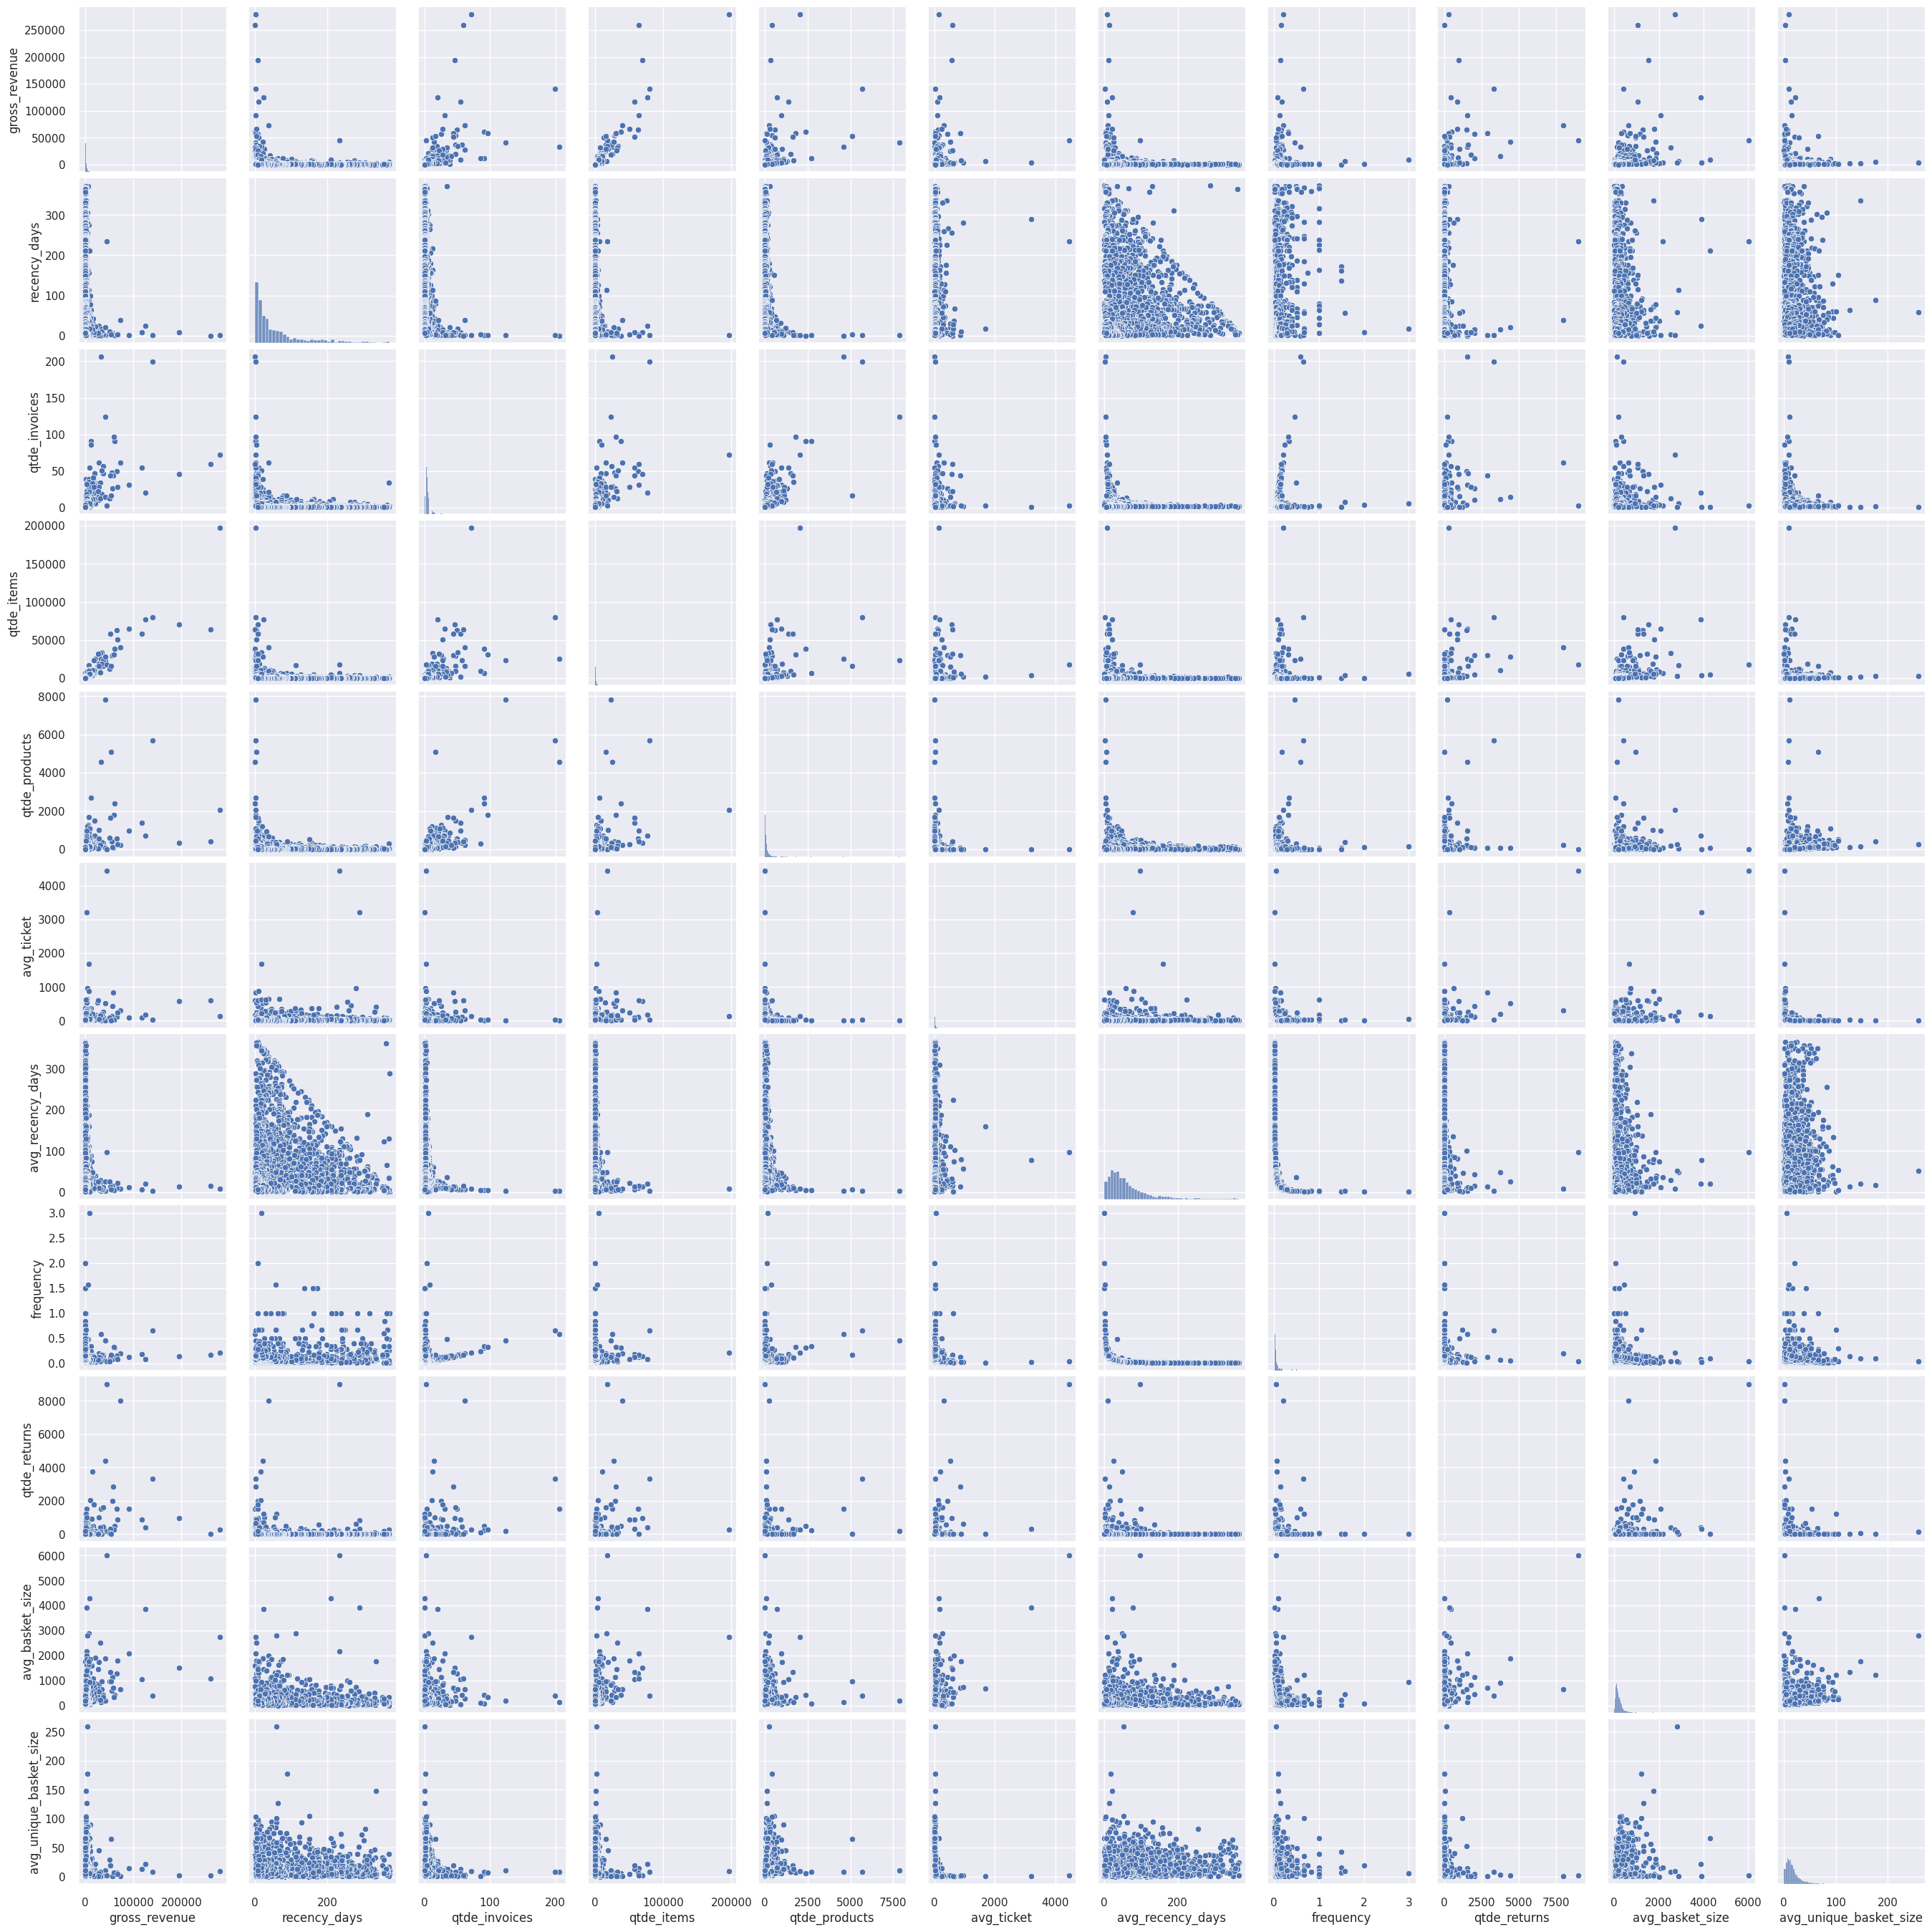

In [56]:
plt.figure( figsize=(25,12) )
sns.pairplot( df42 )

**Notes**

  1. Frequency has low variance


## 4.3. Estudo do Espaço

In [57]:
# original dataset
#df43 = df4.drop( columns=['customer_id'], axis=1 ).copy()

# selected dataset
cols_selected = ['customer_id', 'gross_revenue', 'recency_days', 'qtde_products', 'frequency', 'qtde_returns']
df43 = df4[cols_selected].copy()

In [58]:
mm = pp.MinMaxScaler()

df43['gross_revenue'] = mm.fit_transform( df43[['gross_revenue']] )
df43['recency_days'] = mm.fit_transform( df43[['recency_days']] )
#df43['qtde_invoices'] = mm.fit_transform( df43[['qtde_invoices']] )
#df43['qtde_items'] = mm.fit_transform( df43[['qtde_items']] )
df43['qtde_products'] = mm.fit_transform( df43[['qtde_products']] )
#df43['avg_ticket'] = mm.fit_transform( df43[['avg_ticket']] )
#df43['avg_recency_days'] = mm.fit_transform( df43[['avg_recency_days']] )
df43['frequency'] = mm.fit_transform( df43[['frequency']] )
df43['qtde_returns'] = mm.fit_transform( df43[['qtde_returns']] )
#df43['avg_basket_size'] = mm.fit_transform( df43[['avg_basket_size']] )
#df43['avg_unique_basket_size'] = mm.fit_transform( df43[['avg_unique_basket_size']] )

X = df43.copy()

In [59]:
X.head()

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns
0,17850,0.019292,0.997319,0.037770,0.160512,0.004438
1,13047,0.011559,0.150134,0.021692,0.014470,0.003883
2,12583,0.024000,0.005362,0.029476,0.013441,0.005547
3,13748,0.003375,0.254692,0.003445,0.004165,0.000000
4,15100,0.003116,0.892761,0.000255,0.043717,0.002441


### 4.3.1. PCA

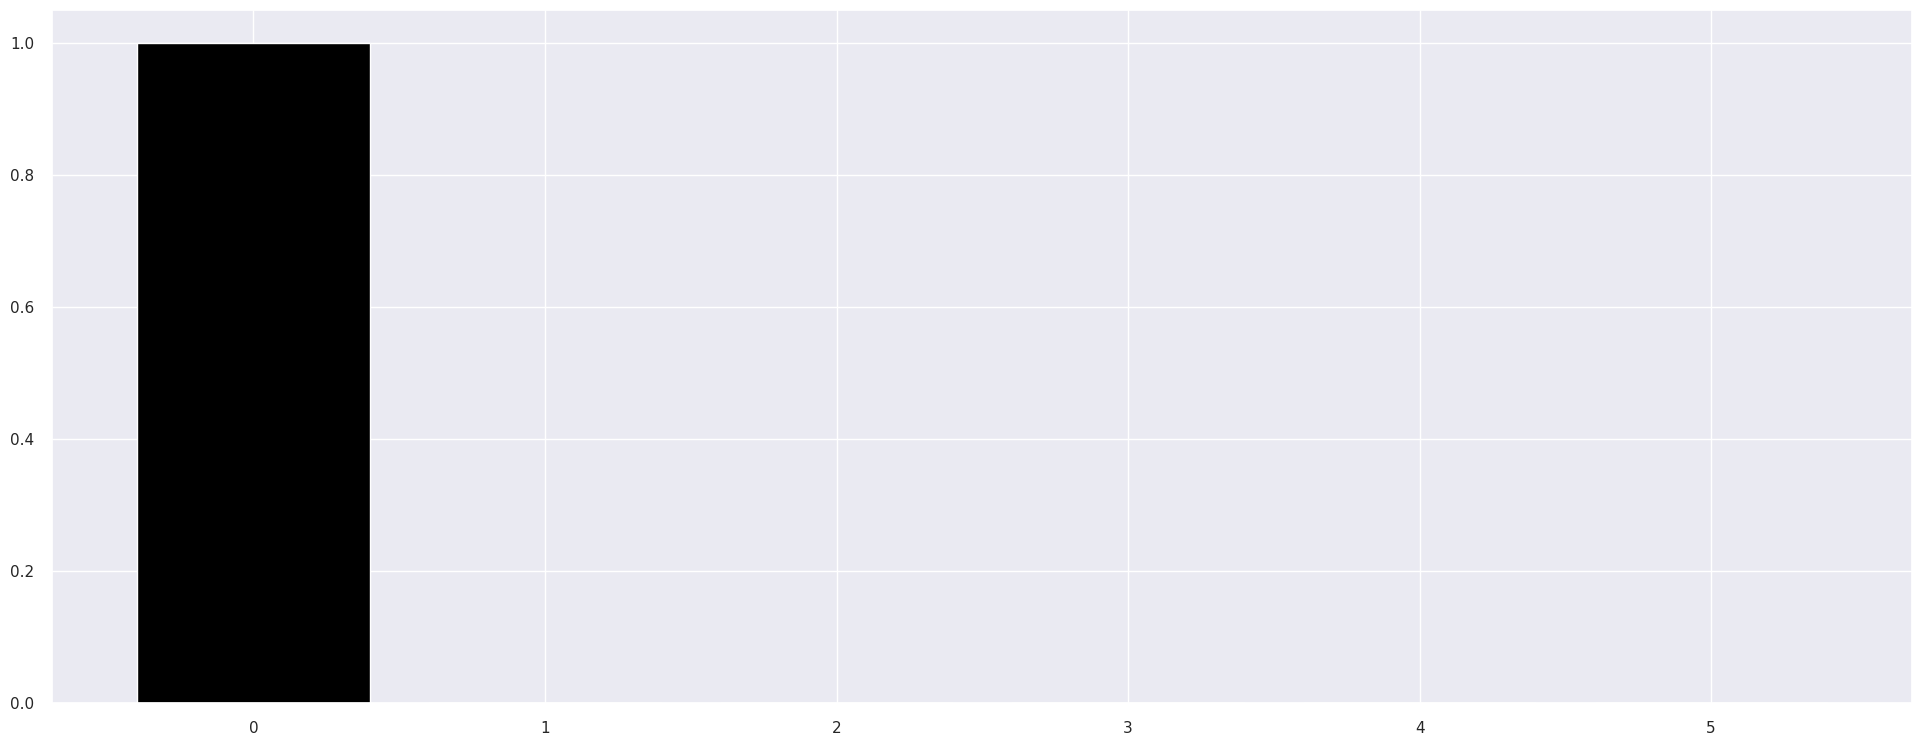

In [60]:
pca = dd.PCA( n_components=X.shape[1] )

principal_components = pca.fit_transform(X)

# plot explained variable
features = range( pca.n_components_ )

plt.bar( features, pca.explained_variance_ratio_, color='black')

# pca component
df_pca = pd.DataFrame( principal_components )

<Axes: xlabel='0', ylabel='1'>

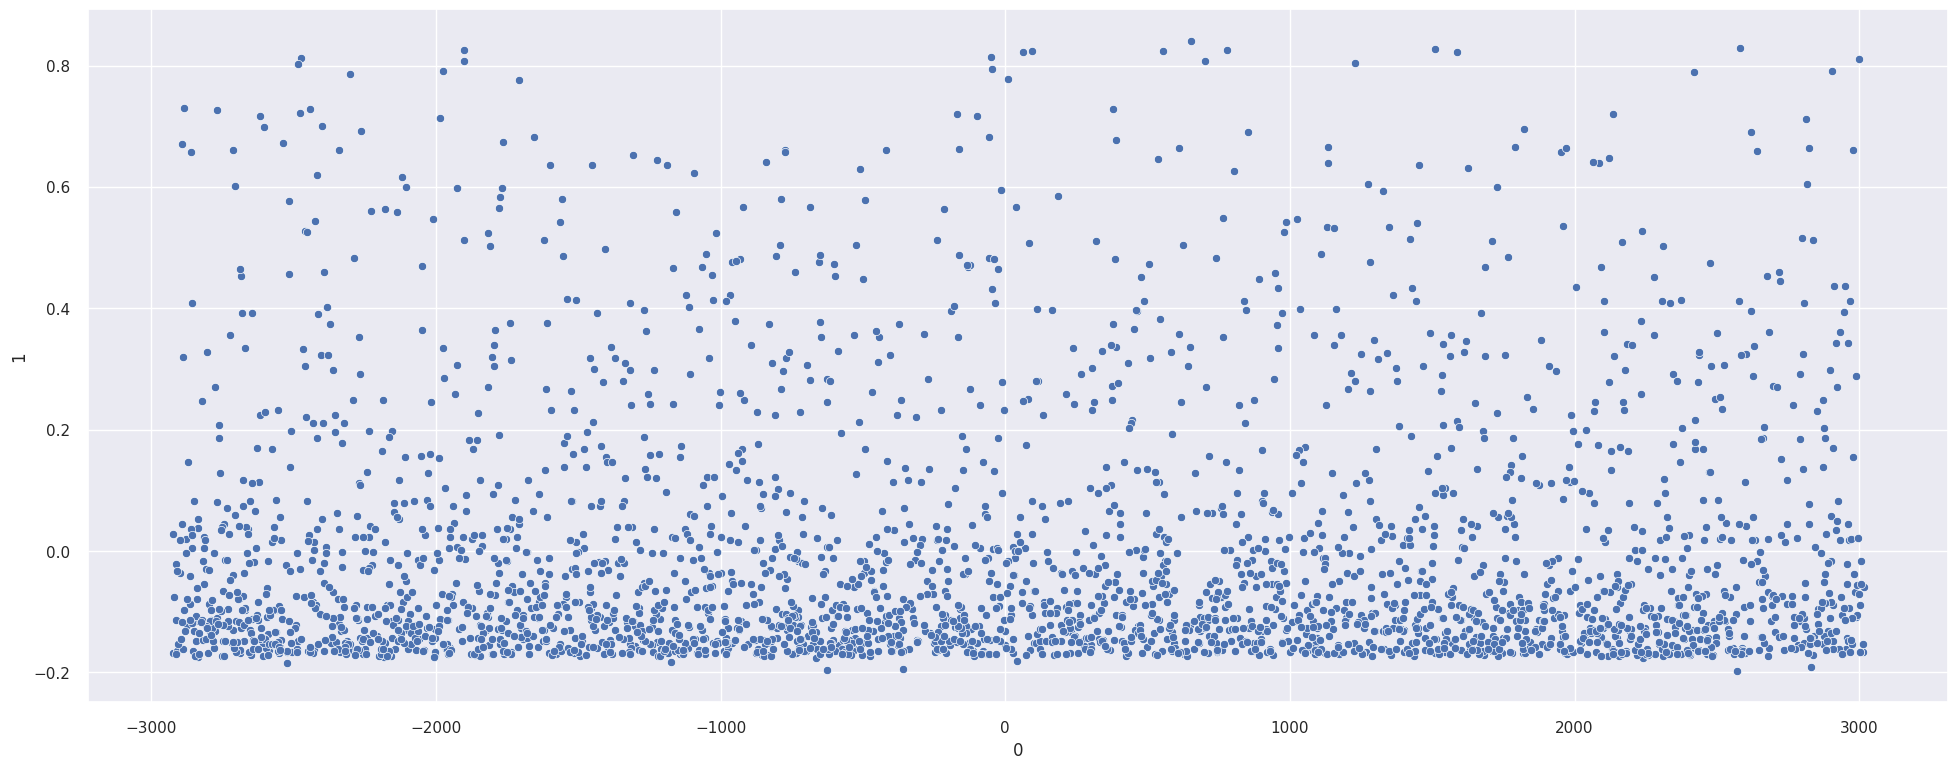

In [61]:
sns.scatterplot( x=0, y=1, data=df_pca)

### 4.3.2. UMAP

/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Axes: xlabel='embedding_x', ylabel='embedding_y'>

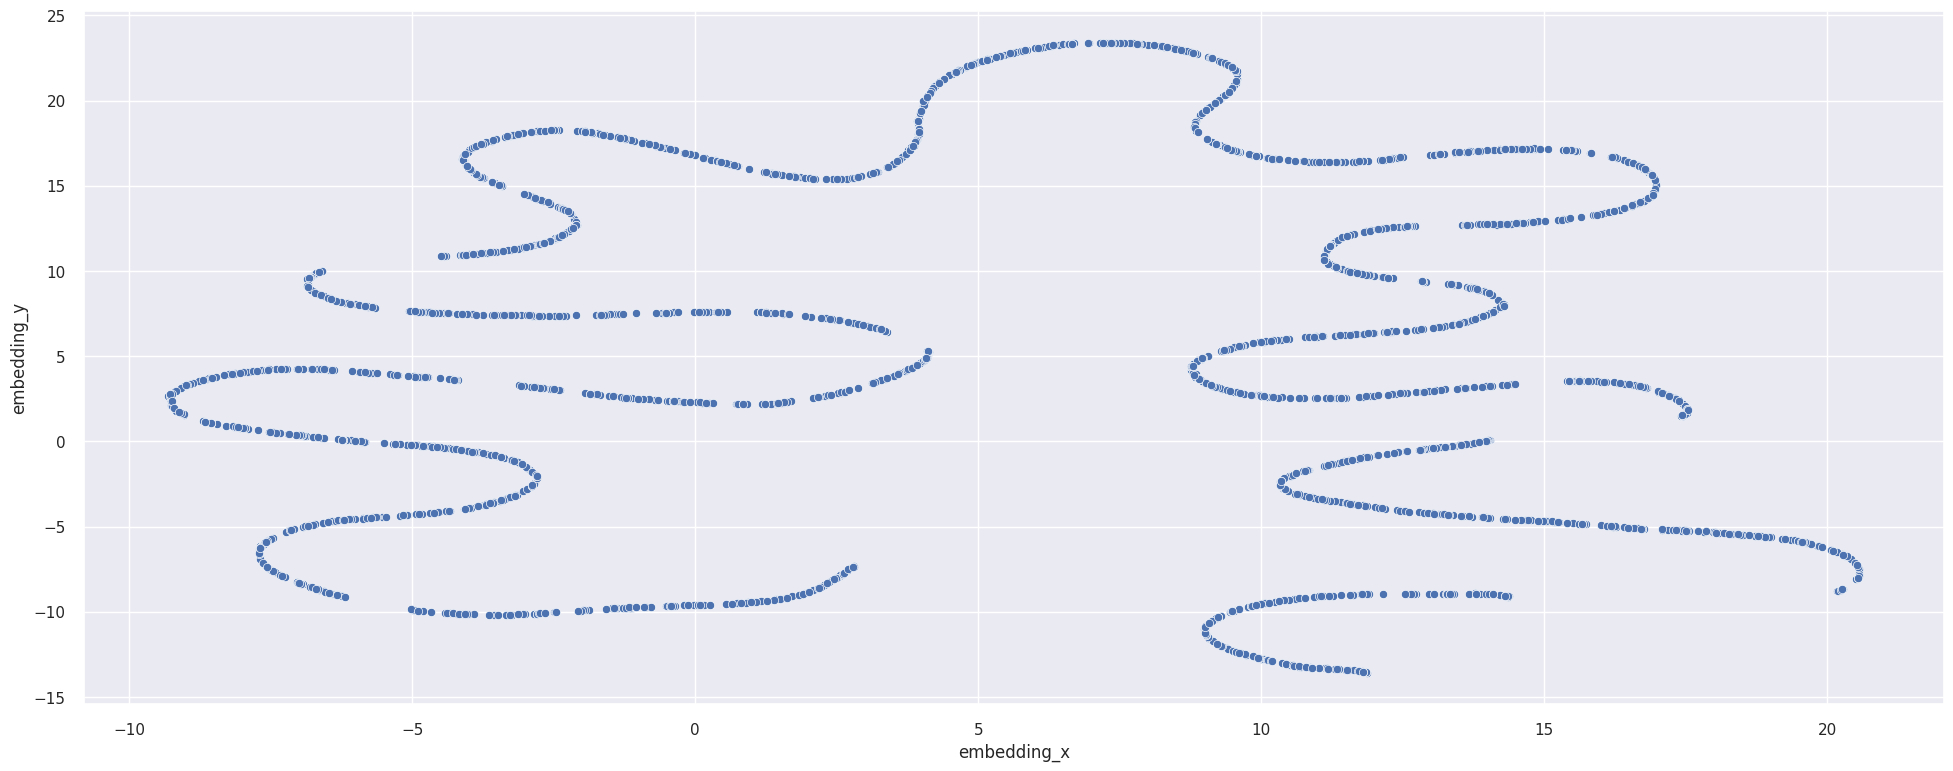

In [62]:
reducer = umap.UMAP( random_state=42 )
embedding = reducer.fit_transform( X )

# embedding
df_pca['embedding_x'] = embedding[:, 0]
df_pca['embedding_y'] = embedding[:, 1]

# plot UMAP
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_pca )

### 4.3.3. t-SNE

<Axes: xlabel='embedding_x', ylabel='embedding_y'>

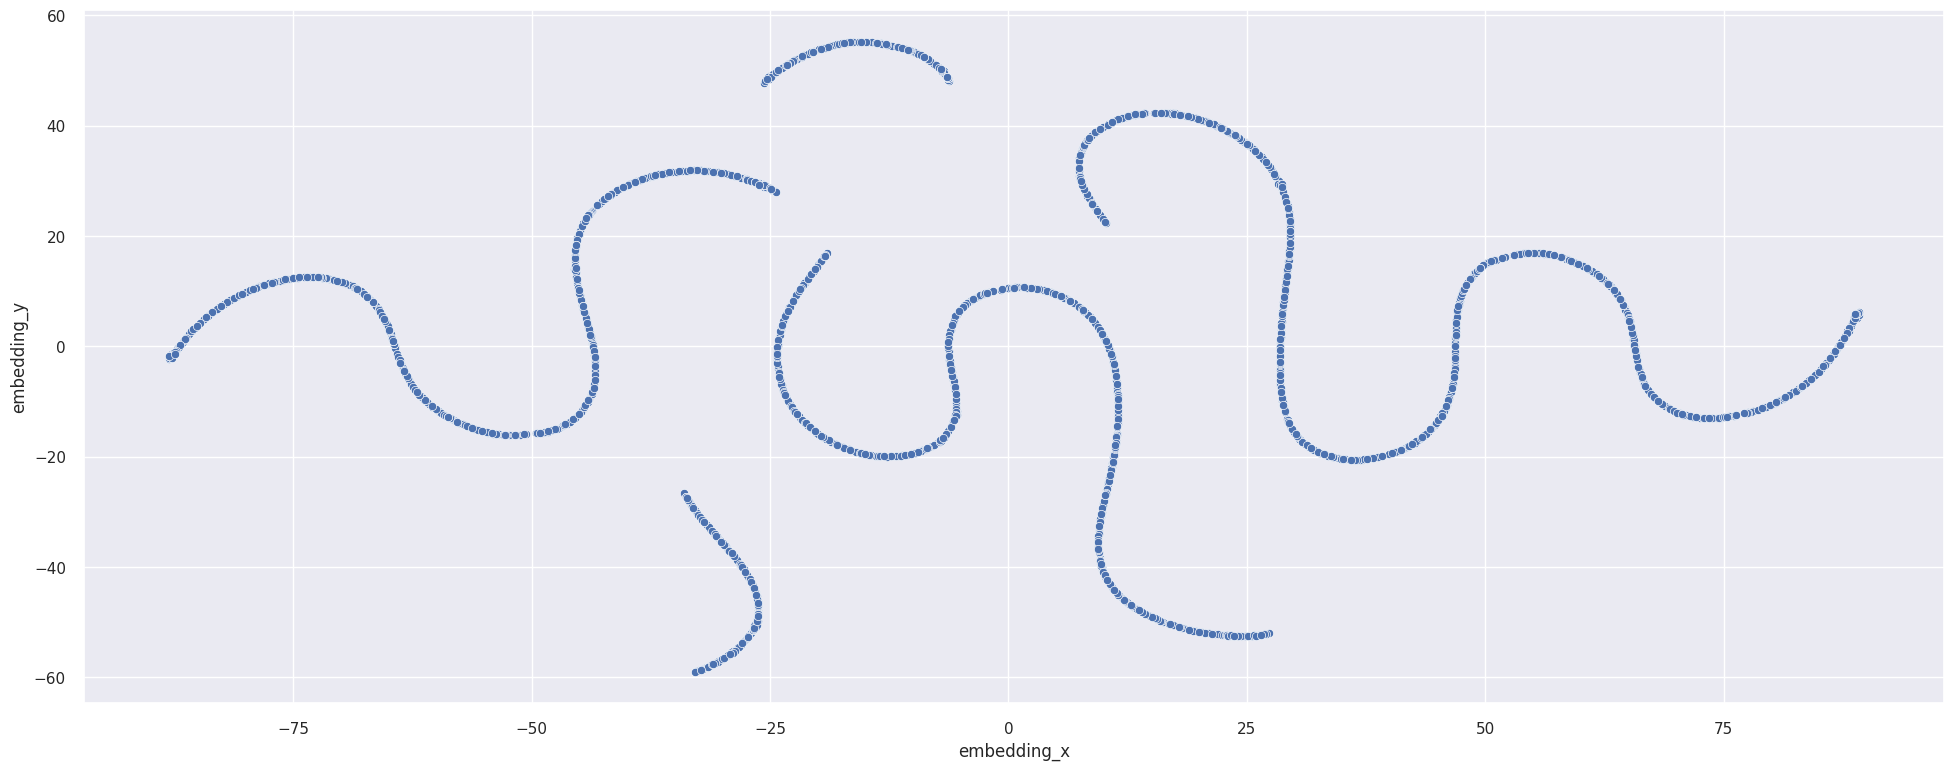

In [63]:
reducer = TSNE( n_components=2, n_jobs=-1, random_state=42 )
embedding = reducer.fit_transform( X )

# embedding
df_pca['embedding_x'] = embedding[:, 0]
df_pca['embedding_y'] = embedding[:, 1]

# plot TSNE
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_pca )

### 4.3.4. Tree-Based Embedding

In [64]:
from sklearn import ensemble as en

In [65]:
# training datasets

X = df43.drop( columns=['customer_id', 'gross_revenue'], axis=1)
y = df43['gross_revenue']

# model definition
rf_model = en.RandomForestRegressor( n_estimators=100, random_state=42 )

# model training
rf_model.fit( X, y)


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [66]:
df_leaf = pd.DataFrame( rf_model.apply(X) )

In [67]:
df_leaf.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99
0,3465,3435,3724,3694,3644,3753,3616,3683,3632,3460,3681,3506,3566,3582,3550,3480,3318,3421,3410,3246,3529,3683,3608,3585,3501,3432,3285,3393,3400,3765,3307,3561,3338,3461,3562,3393,3604,3657,3461,3618,3504,3606,3616,3647,3414,3434,3491,3737,3588,3376,3567,3545,3521,3391,3740,3697,3443,3659,3401,3694,3494,3483,3685,3760,3642,3490,3498,3589,3512,3522,3715,3722,3638,3706,3713,3510,3600,3531,3584,3412,3527,3545,3503,3670,3497,3631,3640,3677,3595,3422,3447,3396,3453,3652,3546,3708,3583,3413,3616,3653
1,3347,3258,3599,3084,3088,3054,3232,3523,3315,3256,3070,3339,3441,3438,3497,3415,3246,3371,3260,3162,3448,3521,3282,3167,3424,3293,3271,3336,3271,3192,3282,3516,3338,3448,3448,3368,3441,3105,3090,3064,3376,3160,3131,3080,3407,3394,3315,3237,3394,3238,3455,3423,3513,3330,3502,3068,3359,3657,3296,3314,3489,3312,3037,3160,3502,3286,3475,3085,3423,3277,3199,3144,3167,3101,3286,3056,3180,3467,3569,3402,3218,3293,3361,3552,3376,3130,3329,3174,3202,3311,3074,3349,3081,2968,3404,2928,3312,3310,3025,3517
2,3478,3171,3618,3571,3555,3650,3153,3554,3259,3272,3576,3362,3414,3396,3470,3454,3293,3338,3434,3228,3427,3514,3217,3272,3444,3415,2997,3327,3288,3611,3264,3404,3318,3496,3499,3468,3424,3560,3415,3536,3535,3210,3527,3597,3098,3429,3345,3248,3142,3379,3450,3492,3461,3470,3541,3629,3484,3545,3333,3216,3388,3417,3577,3661,3425,3384,3250,3531,3467,3044,3639,3630,3654,3614,3138,3513,3266,3457,3599,3232,3275,3220,3396,3523,3393,3530,3011,3714,3323,3451,3394,3314,3474,3432,3525,3591,3119,3375,3521,3602
3,1058,797,1175,430,854,658,546,902,1295,1528,806,395,632,485,1084,928,914,972,359,1070,542,326,1253,317,486,441,1226,618,1166,531,710,609,1209,974,1227,1035,1344,415,324,1280,603,1272,1003,580,1150,1037,396,317,773,950,493,358,1150,785,1337,1154,410,549,874,512,930,1027,994,1100,1092,336,589,859,537,1132,1088,1188,667,1471,1265,864,625,1138,1238,790,1162,1119,1048,1131,344,1035,969,957,621,1114,533,1611,714,798,1203,1276,613,1117,910,897
4,482,420,401,893,919,801,1297,561,644,640,497,784,871,901,530,635,483,69,822,664,843,772,712,821,888,775,652,923,666,892,846,716,520,571,567,463,538,1239,914,761,895,752,726,941,641,355,980,977,987,746,885,829,561,434,738,580,1085,1114,148,1179,708,716,508,553,547,850,695,426,744,714,382,774,997,493,559,1128,972,671,632,689,592,630,552,717,676,482,605,727,1390,690,1026,645,878,555,771,626,907,525,1319,539


/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Axes: xlabel='embedding_x', ylabel='embedding_y'>

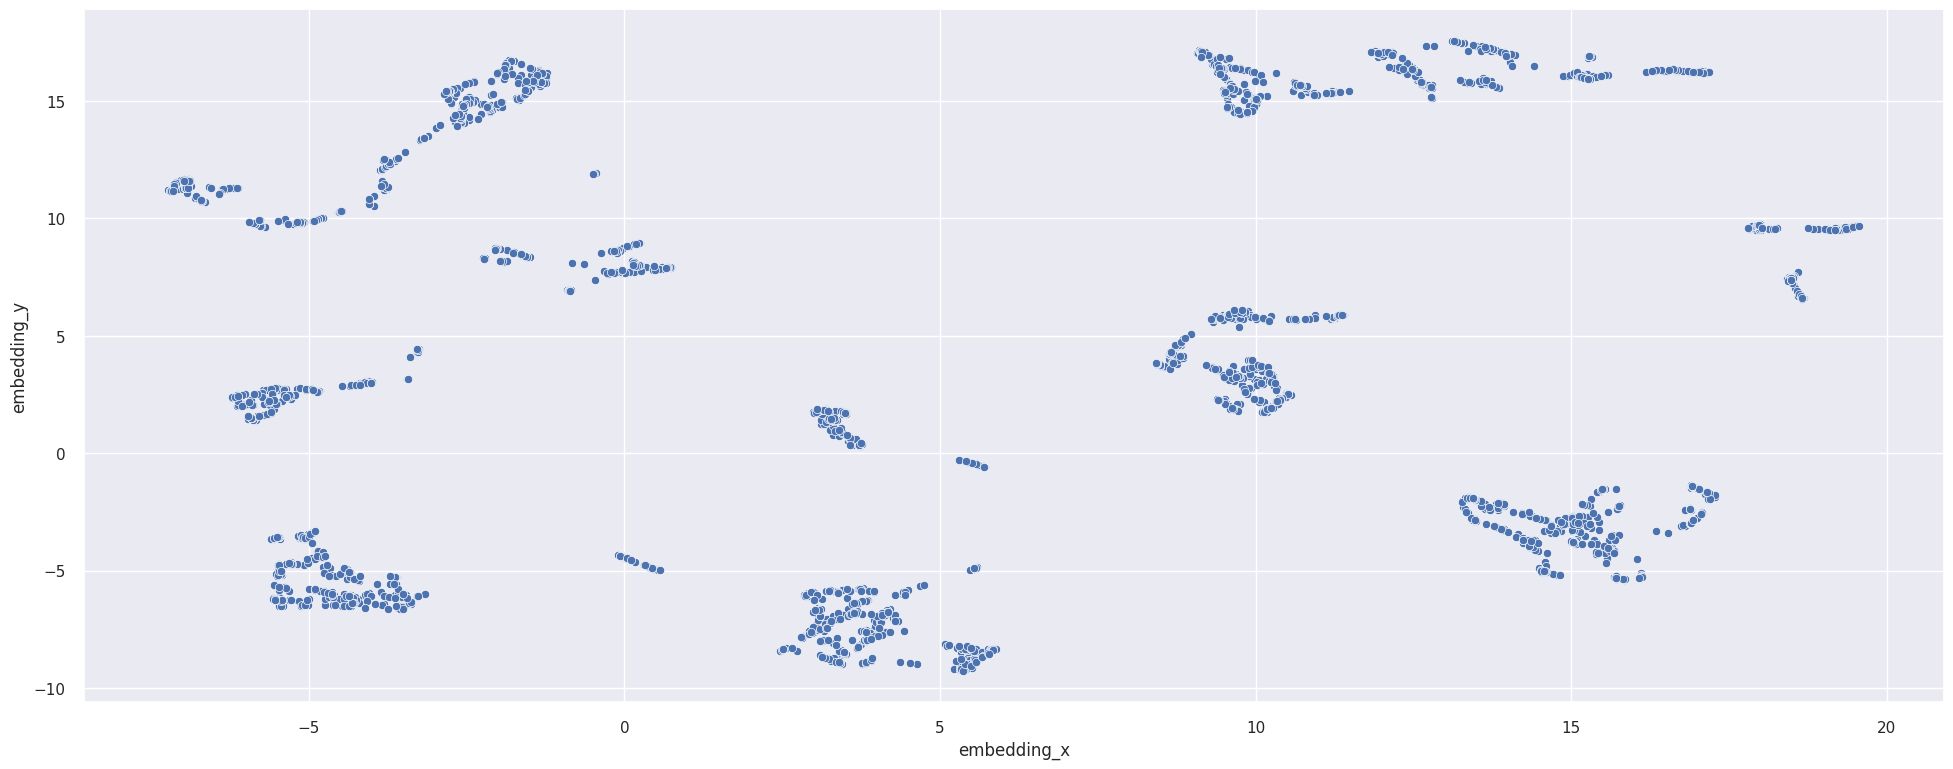

In [68]:
reducer = umap.UMAP( random_state=42 )
embedding = reducer.fit_transform( df_leaf )

# embedding
df_tree = pd.DataFrame()
df_tree['embedding_x'] = embedding[:, 0]
df_tree['embedding_y'] = embedding[:, 1]

# plot UMAP
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_tree)

#  <font color='red'> 5.0. Data Preparation </font>

Padronização (Standadization) -> Premissa que os dados vieram de uma distribuição normal
Reescala     (Rescale)        -> Não Premissa que os dados vieram de uma distribuição normal   

** Regra do Coração **
1. Distribuição Normal e não possui outlier -> Standard Scaler - Média e Desvio padrão
2. Distribuição Normal e possui outlier -> Robust Scaler - Quartis
3. Não Distribuição Normal ->  Min Max Scaler

** Testes de Normalidade **
QQ Plot - Quantile Quantile Plot  ( Quantile Teorica vs Quantile Real)
KS Teste - Kolgomorov Smirnoff (Teste de Hipótese) Se p-value > 0.5 Distribuição Normal, senão não Distribuição Normal

** Detecção Outlier **
Box Plot -> Pontos são identificados como Outliers
IRQ * 2.5 -> Acima desse valor (Outlier)

Z-Score > 3   -> Outliers
Z-Score < -3  -> Outliers


In [69]:
#df5 = df4.copy()
df5 = df_tree.copy()

In [70]:
'''
mm = pp.MinMaxScaler()
ss = pp.StandardScaler()
rs = pp.RobustScaler()

df5['gross_revenue'] = mm.fit_transform( df5[['gross_revenue']] )

df5['recency_days'] = mm.fit_transform( df5[['recency_days']] )

#df5['qtde_invoices'] = mm.fit_transform( df5[['qtde_invoices']] )

#df5['qtde_items'] = mm.fit_transform( df5[['qtde_items']] )

df5['qtde_products'] = mm.fit_transform( df5[['qtde_products']] )

#df5['avg_ticket'] = mm.fit_transform( df5[['avg_ticket']] )

#df5['avg_recency_days'] = mm.fit_transform( df5[['avg_recency_days']] )

df5['frequency'] = mm.fit_transform( df5[['frequency']] )

df5['qtde_returns'] = mm.fit_transform( df5[['qtde_returns']] )

#df5['avg_basket_size'] = mm.fit_transform( df5[['avg_basket_size']] )

#df5['avg_unique_basket_size'] = mm.fit_transform( df5[['avg_unique_basket_size']] )
'''

"\nmm = pp.MinMaxScaler()\nss = pp.StandardScaler()\nrs = pp.RobustScaler()\n\ndf5['gross_revenue'] = mm.fit_transform( df5[['gross_revenue']] )\n\ndf5['recency_days'] = mm.fit_transform( df5[['recency_days']] )\n\n#df5['qtde_invoices'] = mm.fit_transform( df5[['qtde_invoices']] )\n\n#df5['qtde_items'] = mm.fit_transform( df5[['qtde_items']] )\n\ndf5['qtde_products'] = mm.fit_transform( df5[['qtde_products']] )\n\n#df5['avg_ticket'] = mm.fit_transform( df5[['avg_ticket']] )\n\n#df5['avg_recency_days'] = mm.fit_transform( df5[['avg_recency_days']] )\n\ndf5['frequency'] = mm.fit_transform( df5[['frequency']] )\n\ndf5['qtde_returns'] = mm.fit_transform( df5[['qtde_returns']] )\n\n#df5['avg_basket_size'] = mm.fit_transform( df5[['avg_basket_size']] )\n\n#df5['avg_unique_basket_size'] = mm.fit_transform( df5[['avg_unique_basket_size']] )\n"

#  <font color='red'> 6.0. Feature Selection </font>

In [71]:
#cols_selected = ['customer_id','gross_revenue','recency_days','qtde_products','frequency','qtde_returns']

In [72]:
#df6 = df5[cols_selected].copy()
df6 = df_tree.copy()

#  <font color='red'> 7.0. Hyperparameter Fine-Tunning </font>

In [73]:
#X = df6.drop( columns=['customer_id'] )
X = df_tree.copy()

In [74]:
X.head()

,embedding_x,embedding_y
0,12.094170,16.984018
1,19.360355,9.582441
2,13.497025,17.340704
3,-5.538470,2.726382
4,-5.400329,9.920911


In [75]:
# clusters = [2,3,4,5,6,7]
clusters = np.arange(2, 26, 1)

## 7.1. K-Means 

In [76]:
from sklearn import metrics as m

kmeans_list = []
for k in clusters:    
    # model definition
    kmeans_model = c.KMeans( n_clusters=k)
    
    # model training
    kmeans_model.fit( X )
    
    # model predict
    labels = kmeans_model.predict( X )
    
    # model preformance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    kmeans_list.append( sil )

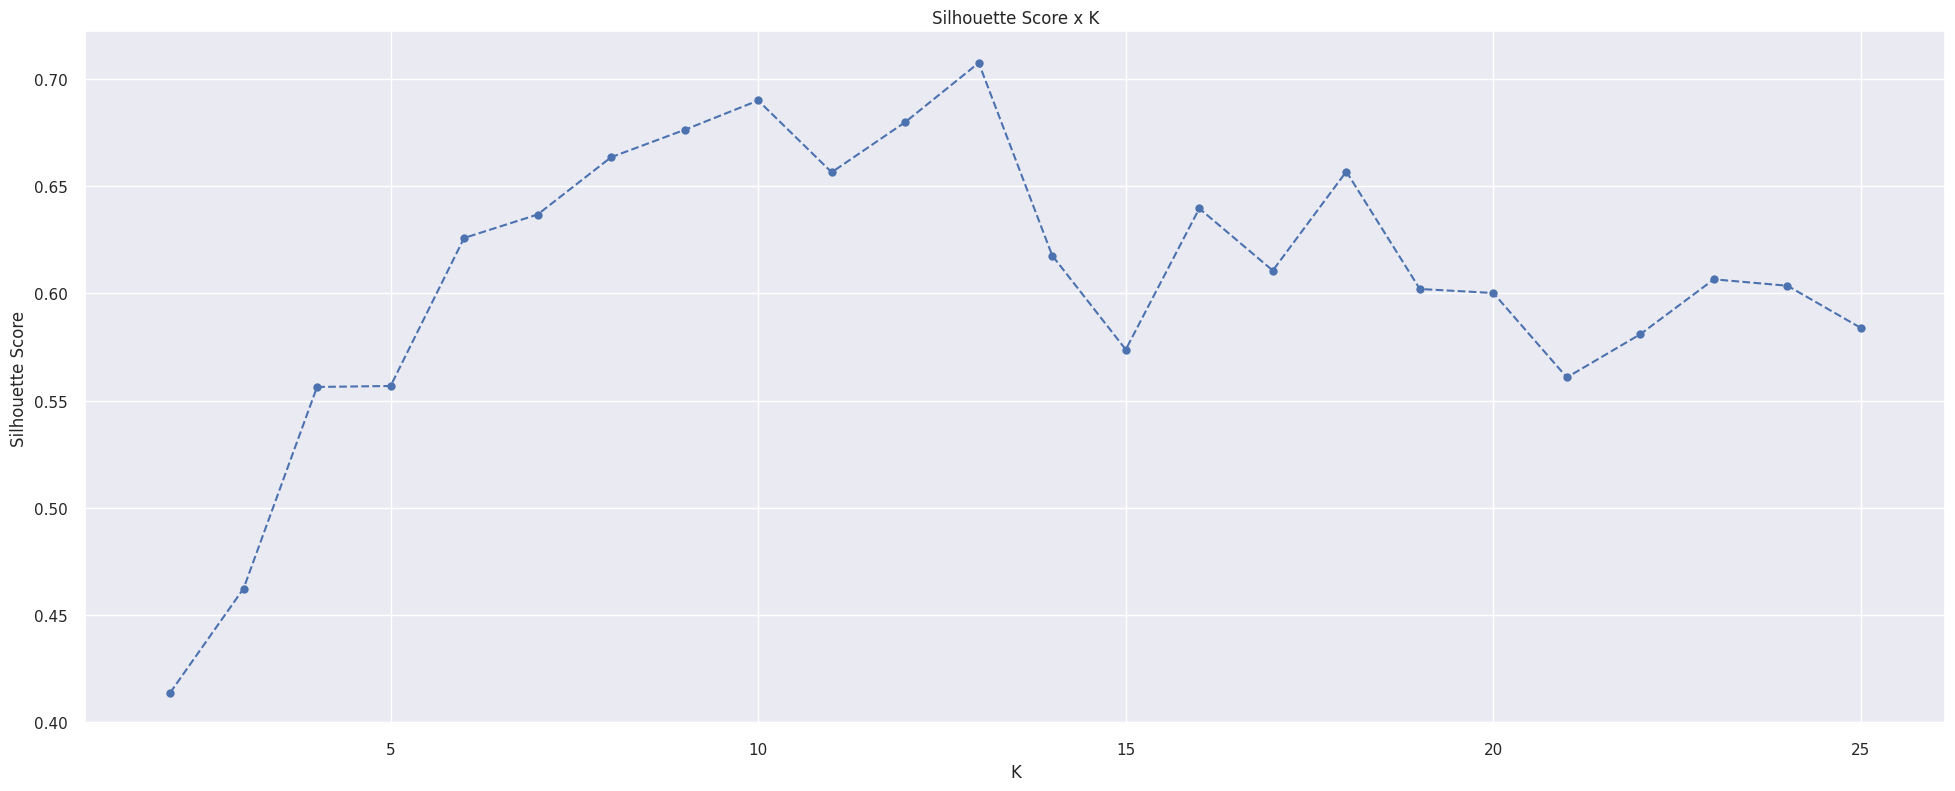

In [77]:
plt.plot( clusters, kmeans_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.2. GMM

In [78]:
from sklearn import mixture as mx

gmm_list = []
for k in clusters:    
    # model definition
    gmm_model = mx.GaussianMixture( n_components=k)
    
    # model training
    gmm_model.fit( X )
    
    # model predict
    labels = gmm_model.predict( X )
    
    # model preformance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    gmm_list.append( sil )

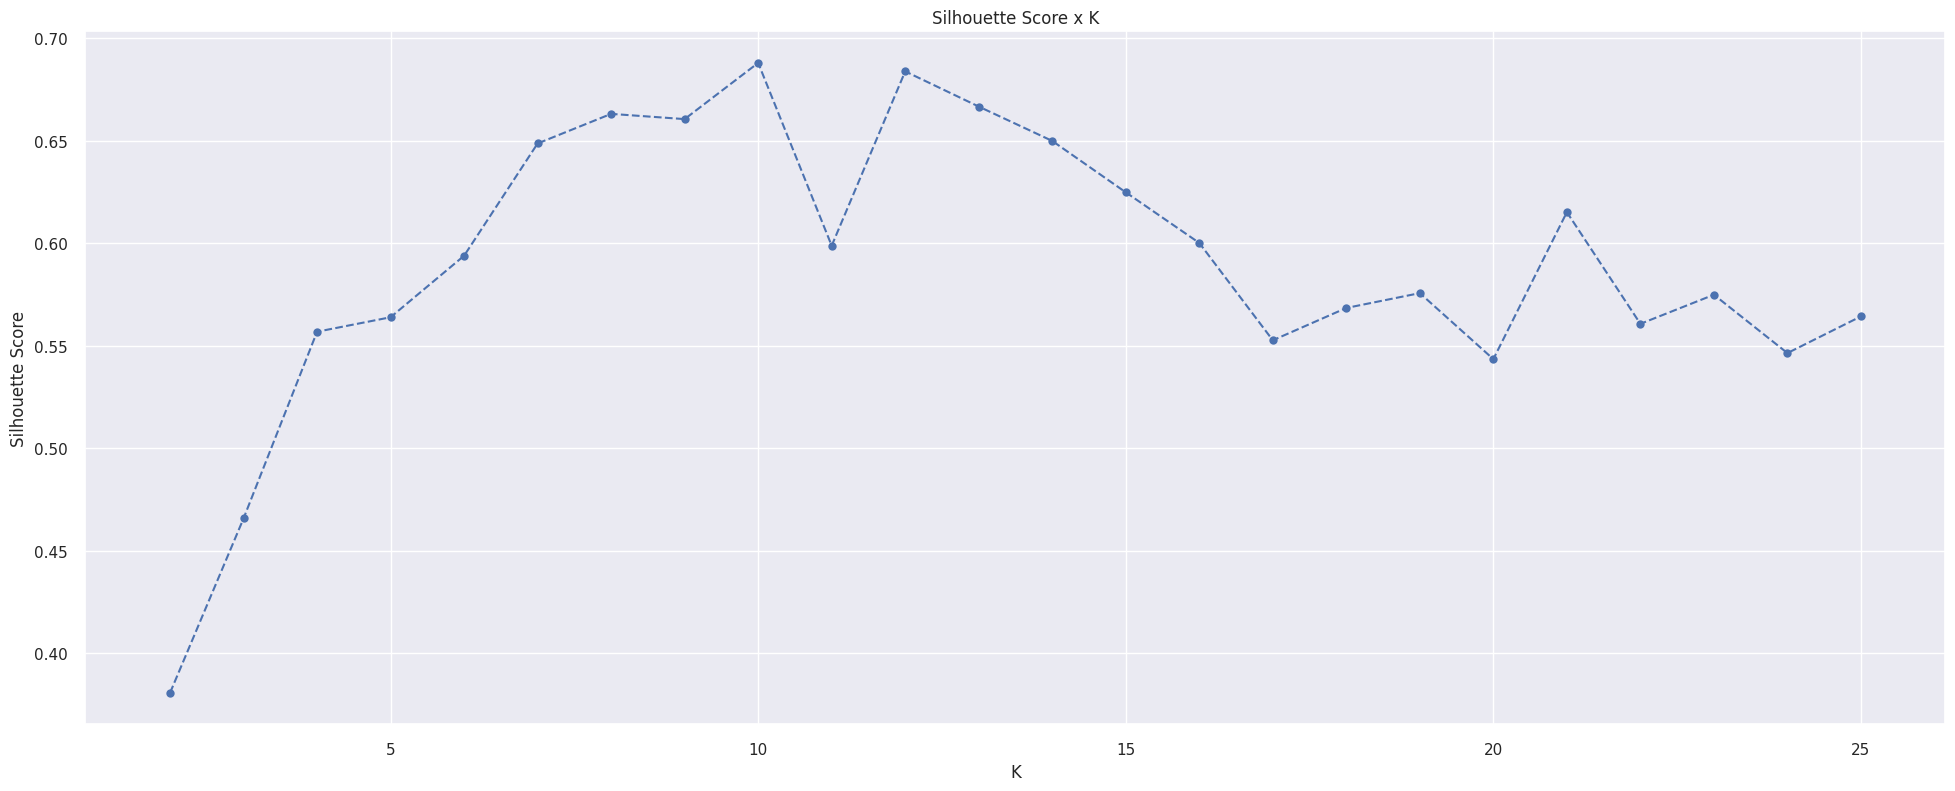

In [79]:
plt.plot( clusters, gmm_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.3. Hierarquical Clustering

In [80]:
from scipy.cluster import hierarchy as hc

In [81]:
# model definition and training
hc_model = hc.linkage( X, 'ward')

In [82]:
#hc.dendrogram(
#    hc_model,
#    leaf_rotation=90,
#    leaf_font_size=8    
#)

#plt.show()

In [83]:
#hc.dendrogram(
#    hc_model,
#    truncate_mode='lastp',
#    p=12,
#    leaf_rotation=90,
#    leaf_font_size=8,
#    show_contracted=True
#)

#plt.show()

### 7.3.1. HClustering Silhouette Score

In [84]:
hc_list = []
for k in clusters: 
    # model definition e training
    hc_model = hc.linkage( X, 'ward')
    
    # model predict
    labels = hc.fcluster( hc_model, k, criterion='maxclust')
    
    # model performance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    hc_list.append( sil )

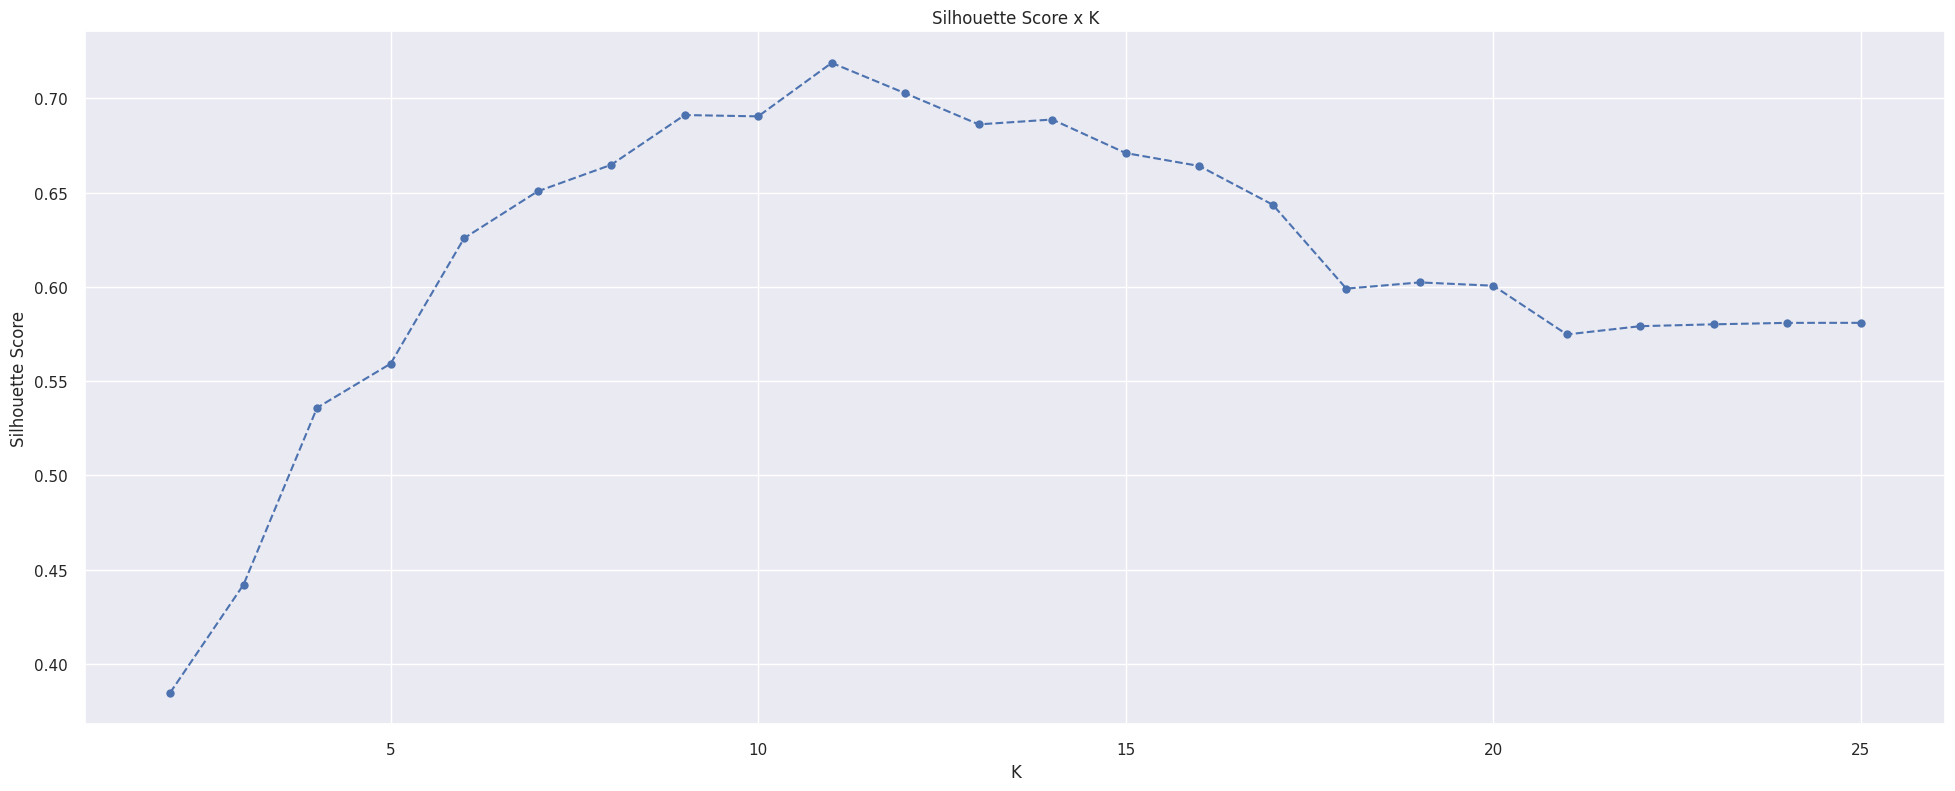

In [85]:
plt.plot( clusters, hc_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.4. DBSCAN

In [86]:
eps=0.5
min_samples=20

# model definition
dbscan_model = c.DBSCAN( eps=eps, min_samples=min_samples )

# model training e prediction
labels = dbscan_model.fit_predict( X )

sil = m.silhouette_score( X, labels, metric='euclidean' )
print( 'Silhouette Score: {}'.format( sil ) )
print( 'Number of Clusters: {}'.format( len( unique( labels ) ) ) )
print( unique(labels) )

Silhouette Score: 0.5506747364997864
Number of Clusters: 31
[-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23 24 25 26 27 28 29]


In [87]:
from sklearn.neighbors import NearestNeighbors

In [88]:
neighbors = NearestNeighbors( n_neighbors=min_samples ).fit( X )
distances, indices = neighbors.kneighbors( X )

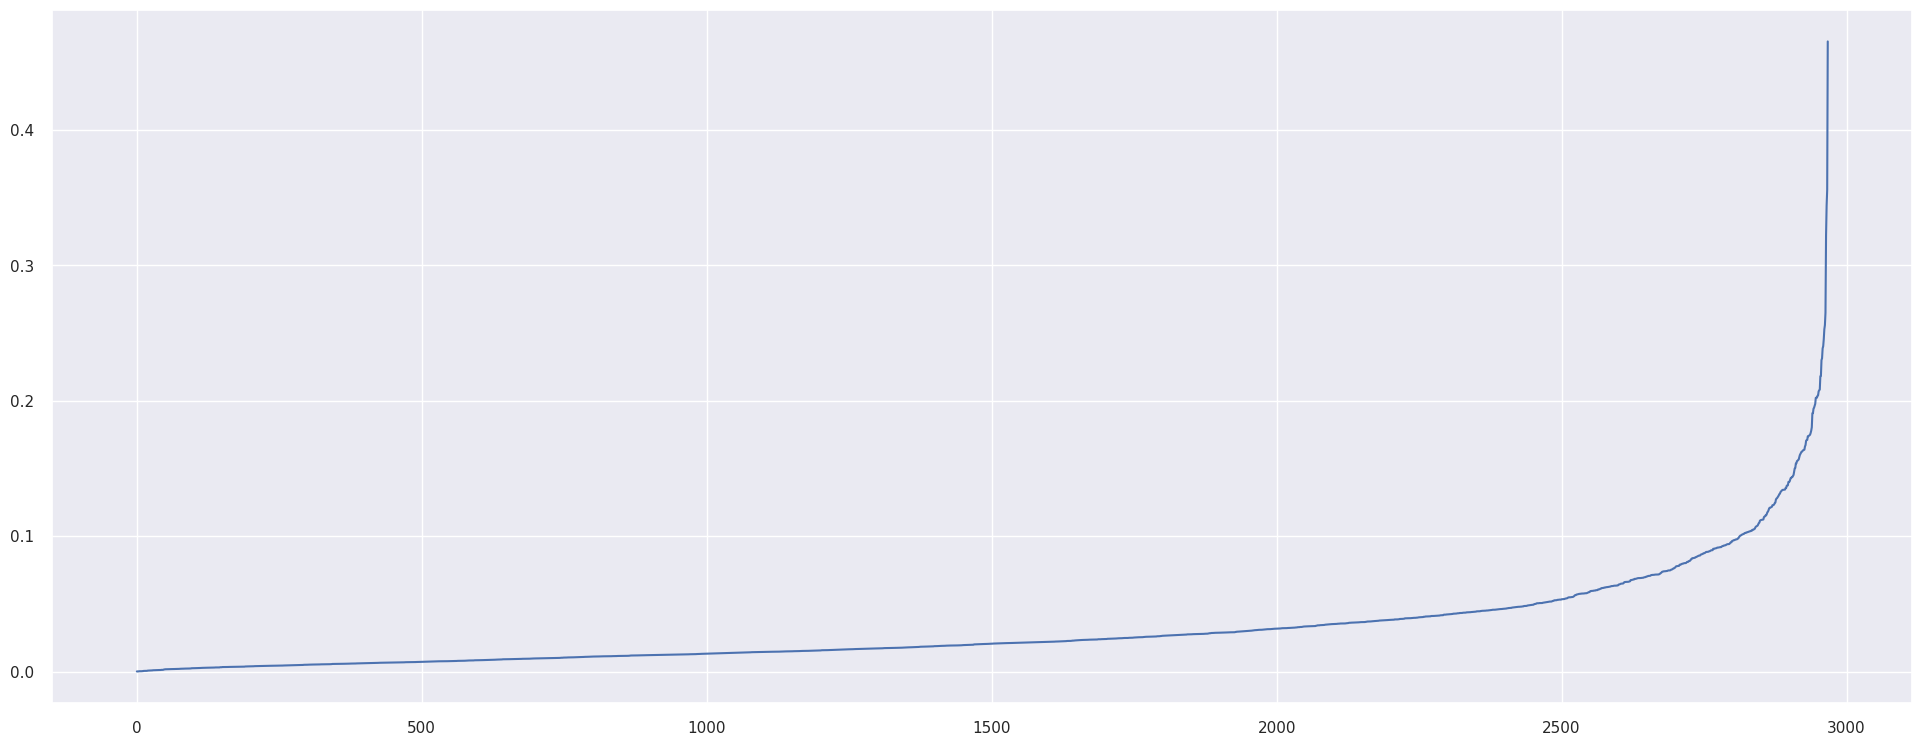

In [89]:
distances = np.sort( distances, axis=0 )
distances = distances[:,1]
plt.plot( distances )

In [90]:
dbscan_list = [0.622034, 0, 0, 0, 0, 0]

## 7.5. Results

In [91]:
# Model Name | k=2 | k=3 | k=4 | k=5 | ...
# KMeans       SS  SS  SS  SS  SS
# GMM          SS  SS  SS  SS  SS
# HC           SS  SS  SS  SS  SS
# DBSCAN       SS  SS  SS  SS  SS

df_results = pd.DataFrame(
    {'Kmeans': kmeans_list,
    'GMM': gmm_list,
    'HC': hc_list
    #'DBSCAN': dbscan_list
        }
).T

df_results.columns = clusters

In [92]:
df_results.style.highlight_max(color='lightgreen', axis=1)

,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
Kmeans,0.413779,0.462418,0.556409,0.556860,0.625855,0.636802,0.663530,0.676290,0.689960,0.656488,0.679870,0.707493,0.617657,0.573843,0.639628,0.610681,0.656831,0.602081,0.600212,0.560849,0.581015,0.606586,0.603603,0.583908
GMM,0.380782,0.465819,0.556828,0.563879,0.593858,0.648588,0.663014,0.660461,0.687863,0.598750,0.683728,0.666577,0.649826,0.624778,0.600099,0.552647,0.568406,0.575639,0.543460,0.615102,0.560670,0.574859,0.546418,0.564300
HC,0.384589,0.442043,0.535884,0.559270,0.625855,0.650717,0.664795,0.691212,0.690511,0.718884,0.702768,0.686258,0.688836,0.671027,0.664174,0.643608,0.599105,0.602399,0.600650,0.574786,0.579181,0.580165,0.580938,0.580949


## 7.1. Silhouette Analysis

For K = 2, Silhouette Score: 0.3845888674259186


/tmp/ipykernel_31309/1994936805.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap( 'Spectral' )


For K = 3, Silhouette Score: 0.44204333424568176


/tmp/ipykernel_31309/1994936805.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap( 'Spectral' )


For K = 4, Silhouette Score: 0.5358839631080627


/tmp/ipykernel_31309/1994936805.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap( 'Spectral' )


... (34 outputs left out)

For K = 24, Silhouette Score: 0.5809380412101746


/tmp/ipykernel_31309/1994936805.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap( 'Spectral' )


For K = 25, Silhouette Score: 0.5809485912322998


/tmp/ipykernel_31309/1994936805.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap( 'Spectral' )


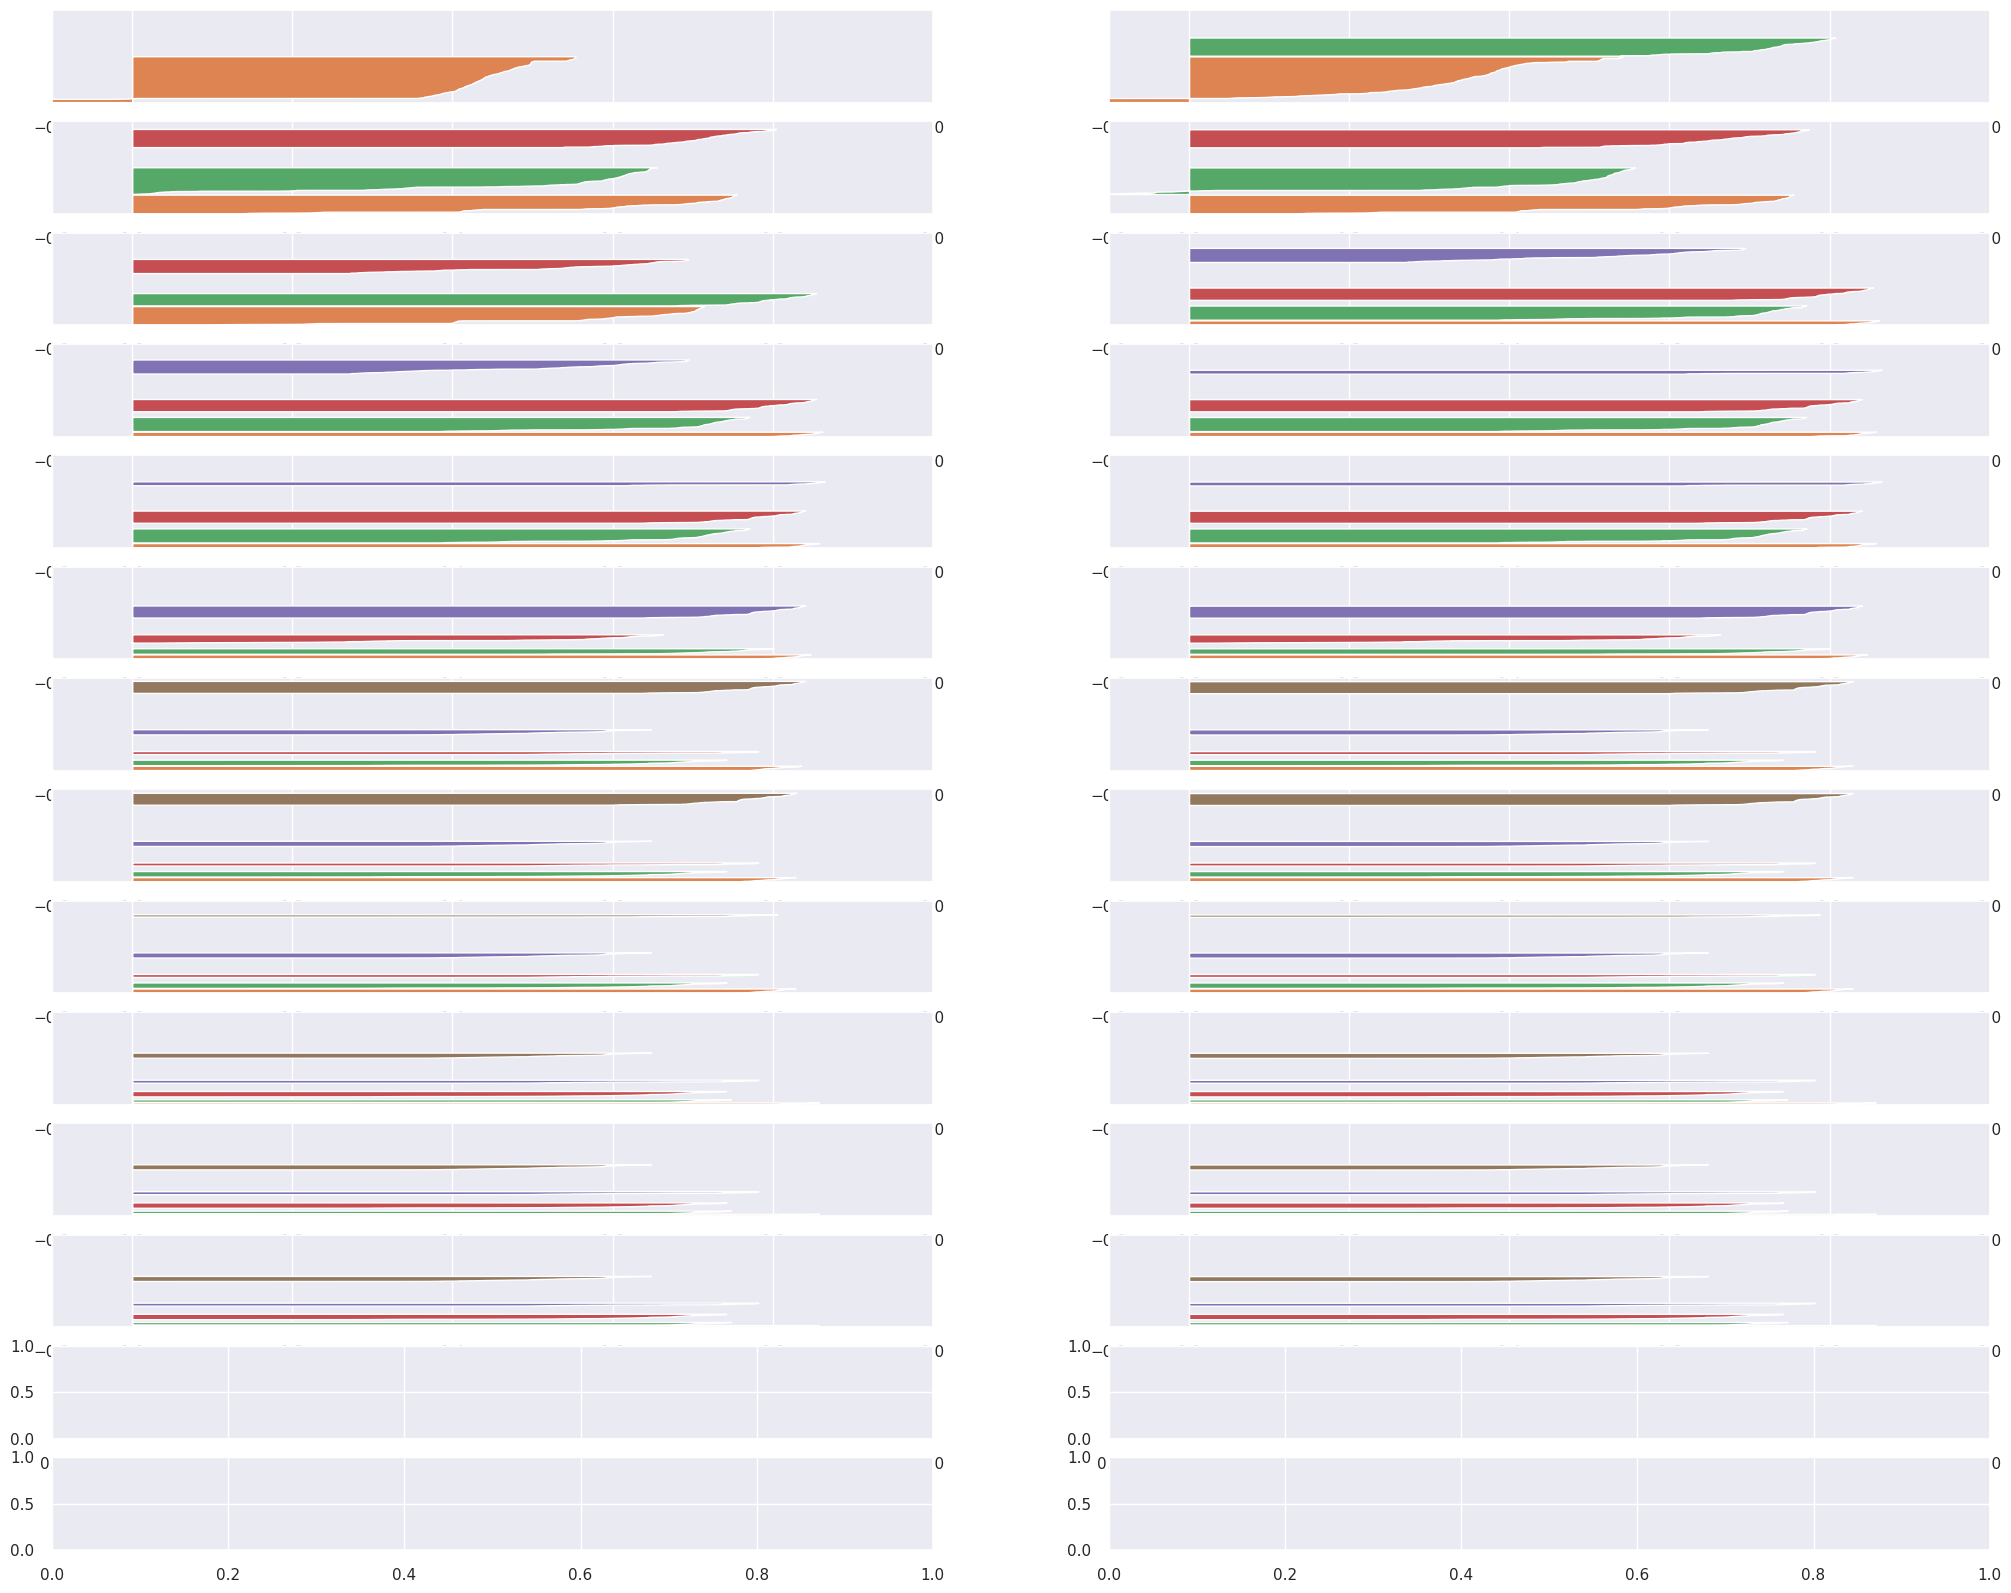

In [93]:
fig, ax = plt.subplots(14, 2)
fig.set_size_inches(25, 20)

for k in clusters:
    q, mod = divmod( k, 2)

    ax[q-1, mod].set_xlim( [ -0.1, 1] )
    ax[q-1, mod].set_ylim( [ 0, len( X ) + (k+1)*10] )
    
    # model definition and training
    hc_model = hc.linkage(X, 'ward')
    
    # model predict
    labels = hc.fcluster( hc_model, k, criterion='maxclust')
    
    # performance
    ss = m.silhouette_score( X, labels, metric='euclidean')
    
    samples_silhouette_values = m.silhouette_samples( X, labels) 
    print( 'For K = {}, Silhouette Score: {}'.format( k, ss))

    y_lower = 10
    for i in range(k):
        
        # select clusters
        ith_samples_silhouette_values = samples_silhouette_values[ labels == i ]

        # sort values
        ith_samples_silhouette_values.sort()
        
        # size clusters
        size_cluster_i = ith_samples_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        cmap = cm.get_cmap( 'Spectral' )
        color = cmap( i / k )
                      
        ax[q-1, mod].fill_betweenx( np.arange( y_lower, y_upper), 0, ith_samples_silhouette_values )

        y_lower = y_lower + y_upper 

    ax[q-1, mod].set_yticks([])
    ax[q-1, mod].set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

## 7.1. Within-Cluster Sum of Square ( WSS )

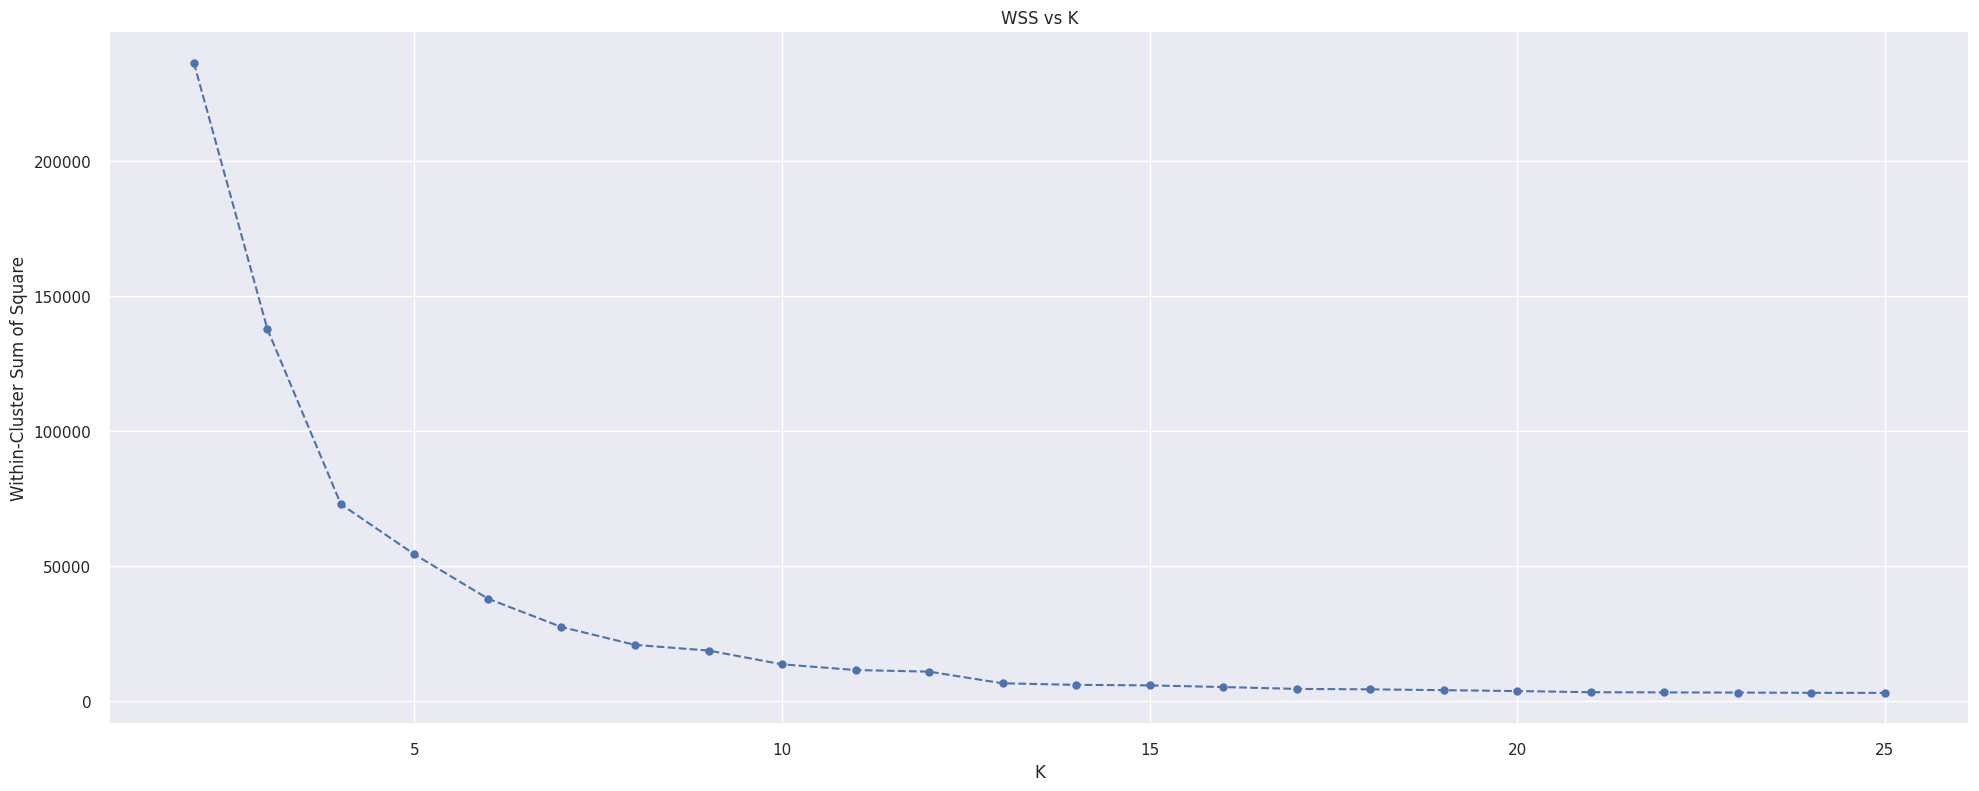

In [94]:
wss = []
for k in clusters:
    # model definition
    kmeans = c.KMeans( init='random', n_clusters=k, n_init=10, max_iter=300, random_state=42 )
    
    # model training
    kmeans.fit( X )
    
    # validation
    wss.append( kmeans.inertia_ )

# plot wss - Elbow Method
plt.plot( clusters, wss, linestyle='--', marker='o', color='b' )
plt.xlabel( 'K' );
plt.ylabel( 'Within-Cluster Sum of Square' );
plt.title( 'WSS vs K' );

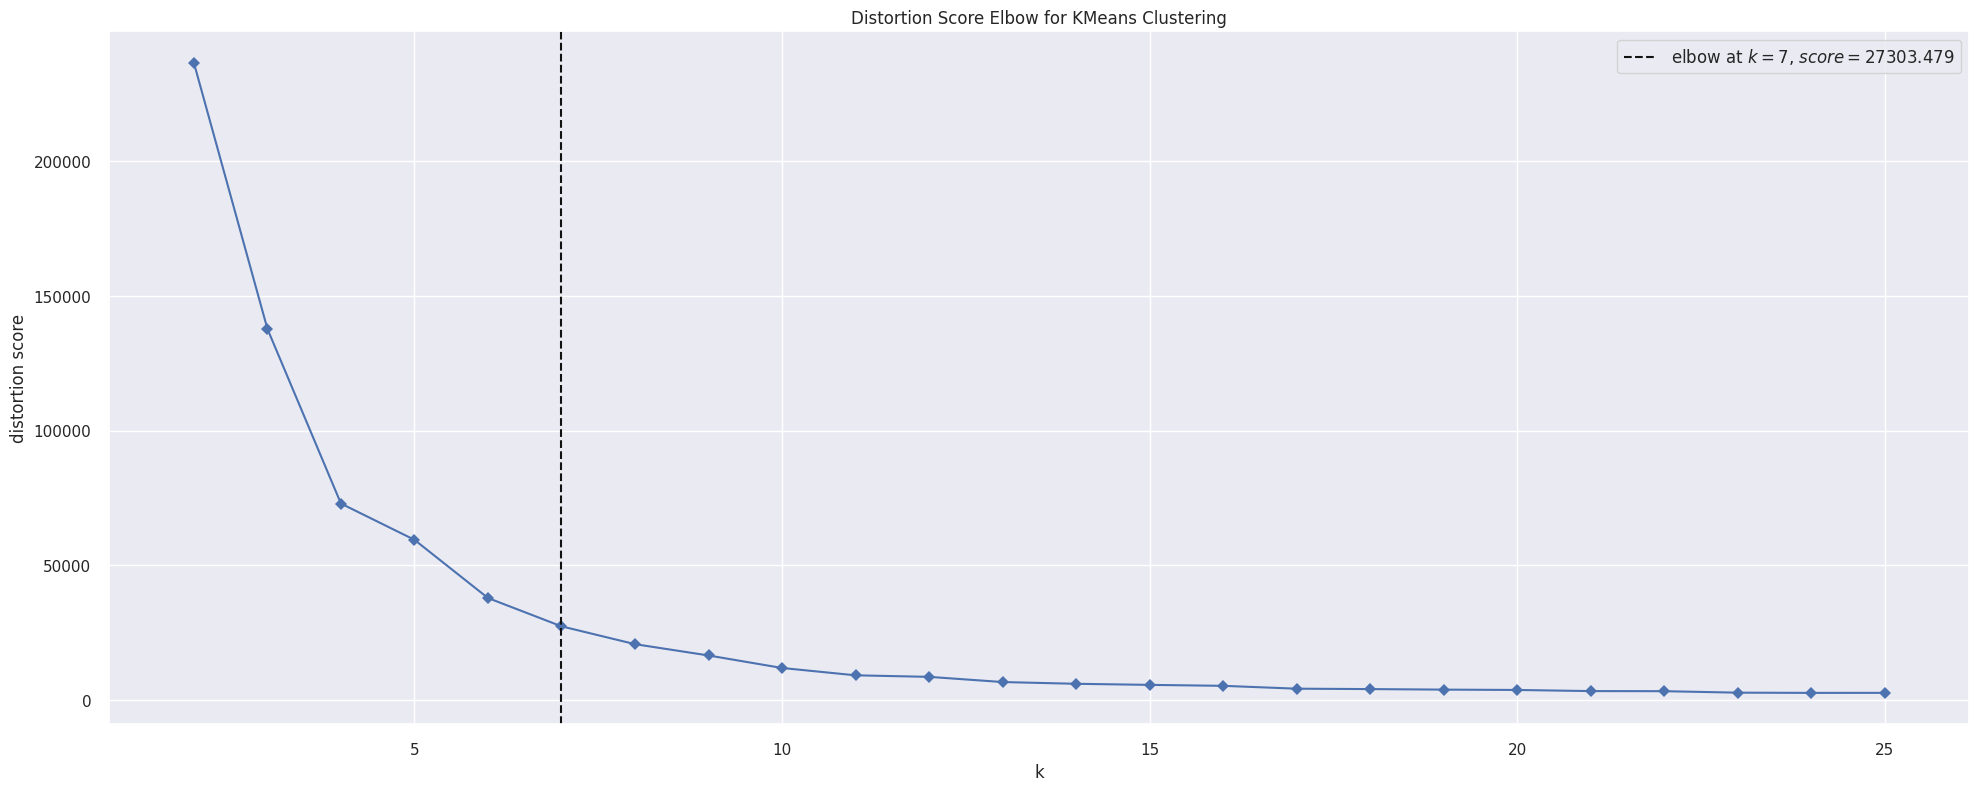

In [95]:
kmeans = KElbowVisualizer( c.KMeans(), k=clusters, timings=False)
kmeans.fit( X )
kmeans.show();

## 7.2. Sillhouette Score

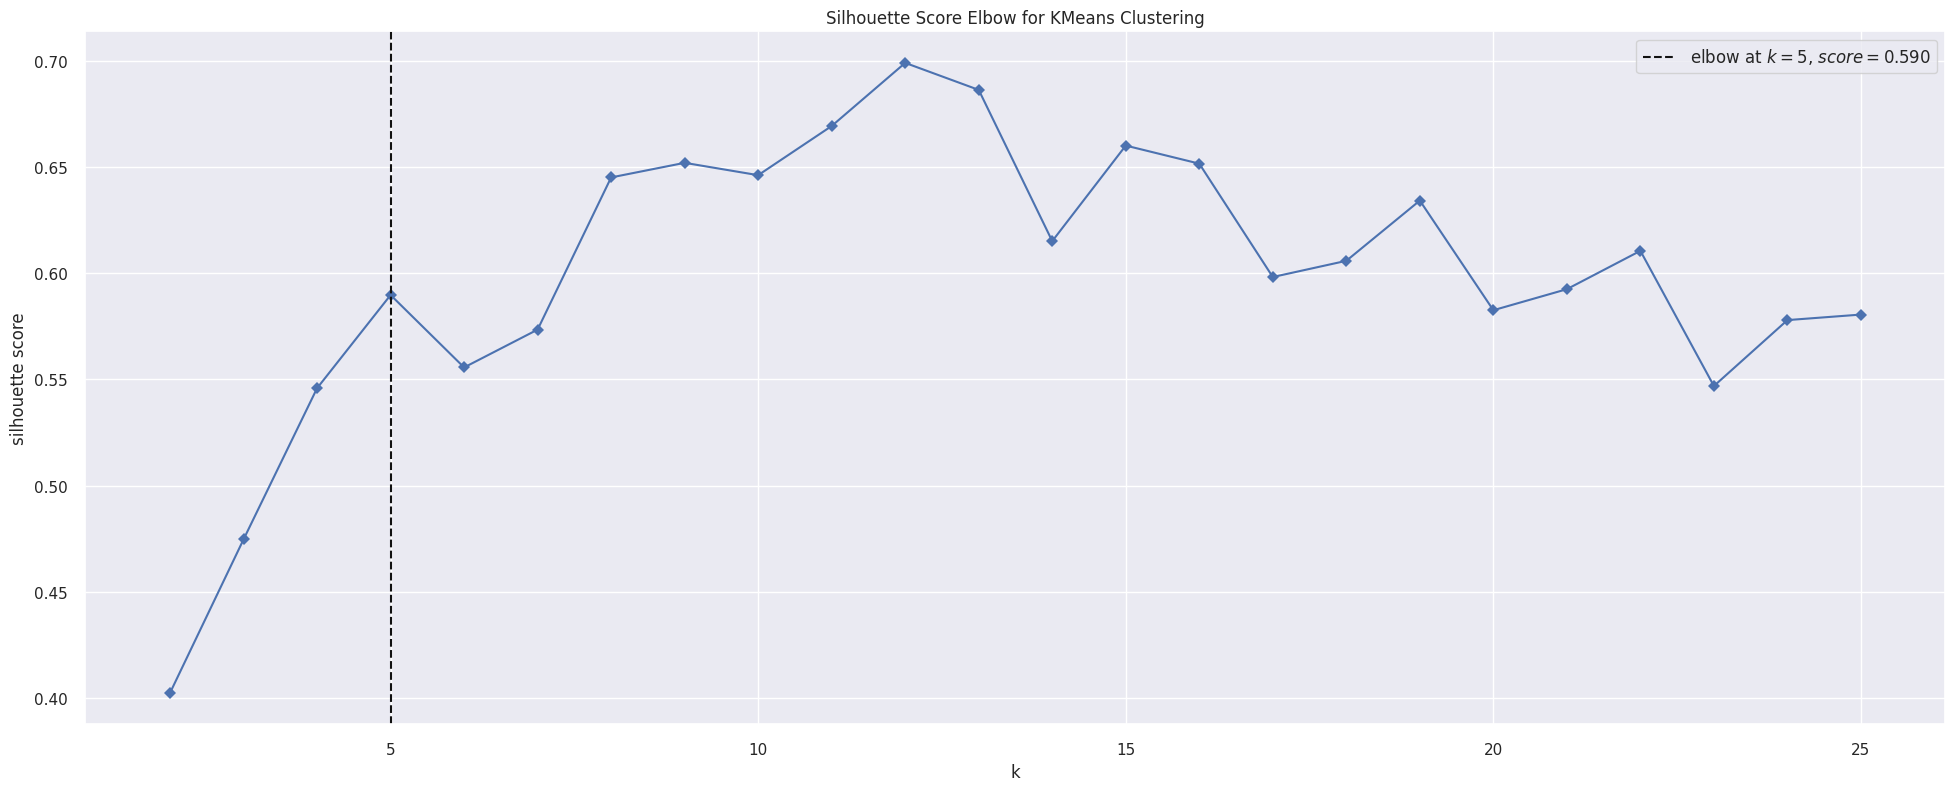

In [96]:
kmeans = KElbowVisualizer( c.KMeans(), k=clusters, metric='silhouette', timings=False)
kmeans.fit( X )
kmeans.show();

## 7.1. Silhouette Analysis

In [97]:
'''
fig, ax = plt.subplots( 3, 2, figsize=(25, 18) )

for k in clusters:
    km = c.KMeans( init='random', n_clusters=k, n_init=10, max_iter=100, random_state=42)
    q, mod = divmod( k, 2)
    
    visualizer = SilhouetteVisualizer( km, color='yellowbrick', ax=ax[q-1][mod])
    visualizer.fit( X )
    visualizer.finalize()
'''

"\nfig, ax = plt.subplots( 3, 2, figsize=(25, 18) )\n\nfor k in clusters:\n    km = c.KMeans( init='random', n_clusters=k, n_init=10, max_iter=100, random_state=42)\n    q, mod = divmod( k, 2)\n    \n    visualizer = SilhouetteVisualizer( km, color='yellowbrick', ax=ax[q-1][mod])\n    visualizer.fit( X )\n    visualizer.finalize()\n"

#  <font color='red'> 8.0. Model Training </font>

## 8.1. K-Means

In [98]:
# model definition
k = 8
#kmeans = c.KMeans( init='random', n_clusters=k, n_init=10, max_iter=300, random_state=42)
#
## model training
#kmeans.fit( X )
#
## clustering
#labels = kmeans.labels_

In [99]:
# model definition
gmm_model = mx.GaussianMixture( n_components=k, random_state=42 )

# model training
gmm_model.fit( X )

# model predict
labels = gmm_model.predict( X ) 

In [100]:
# index of new cluster name
#idx = np.argsort( gmm_model.means_.sum(axis = 1) )
#
# new cluster label
#new_cluster_label = np.zeros_like( idx )
#
# cluster name
#cluster_name = [10, 11, 12, 13, 14, 15, 16, 17]
#
#labels = new_cluster_label[ labels ]
#new_cluster_label[idx] = cluster_name
#labels = new_cluster_label[ labels ]

## 8.2. Cluster Validation

In [101]:
from sklearn import metrics as m

## WSS (Within-cluster sum of square)
print( 'WSS value: {}'.format( kmeans.inertia_ ) )

## SS (Silhouette Score)
print( 'SS value: {}'. format( m.silhouette_score( X, labels, metric='euclidean' ) ) )

WSS value: 2534.693359375
SS value: 0.6618000864982605


#  <font color='red'> 9.0. Cluster Analysis </font>

In [102]:
X.head()

,embedding_x,embedding_y
0,12.094170,16.984018
1,19.360355,9.582441
2,13.497025,17.340704
3,-5.538470,2.726382
4,-5.400329,9.920911


In [103]:
df9 = X.copy()
df9['cluster'] = labels

In [104]:
#df9 = df4.copy()
#df9['cluster'] = labels
df9.head()

,embedding_x,embedding_y,cluster
0,12.094170,16.984018,3
1,19.360355,9.582441,7
2,13.497025,17.340704,3
3,-5.538470,2.726382,6
4,-5.400329,9.920911,2


## 9.1. Visualization Inspection

<Axes: xlabel='embedding_x', ylabel='embedding_y'>

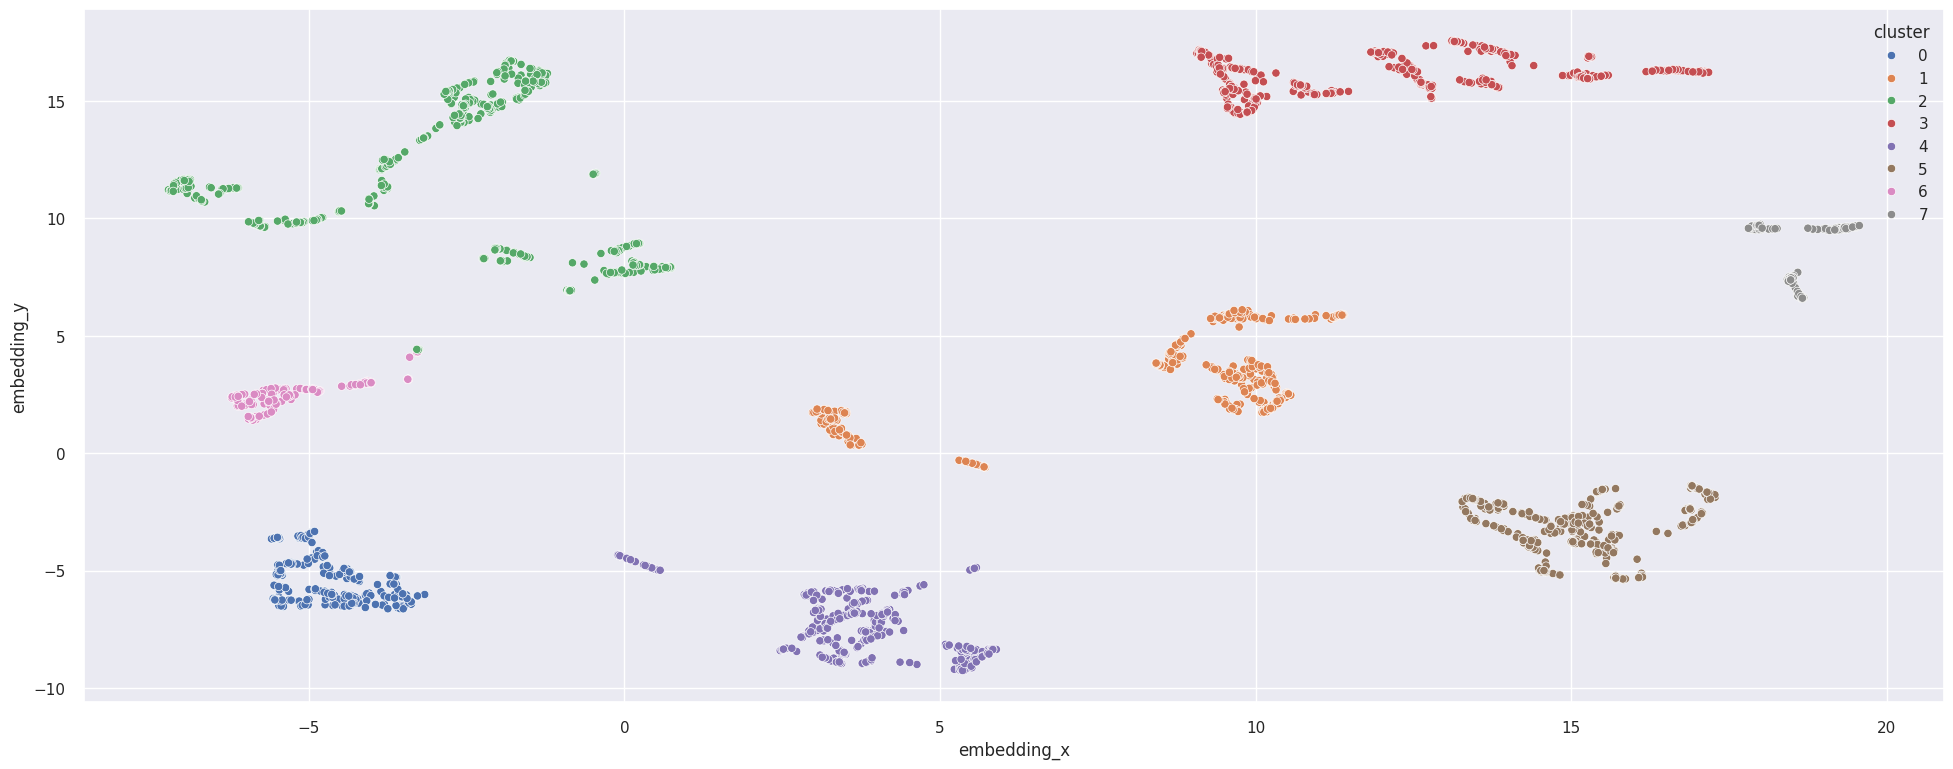

In [105]:
sns.scatterplot( x='embedding_x', y='embedding_y', hue='cluster', data=df9, palette='deep')

/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


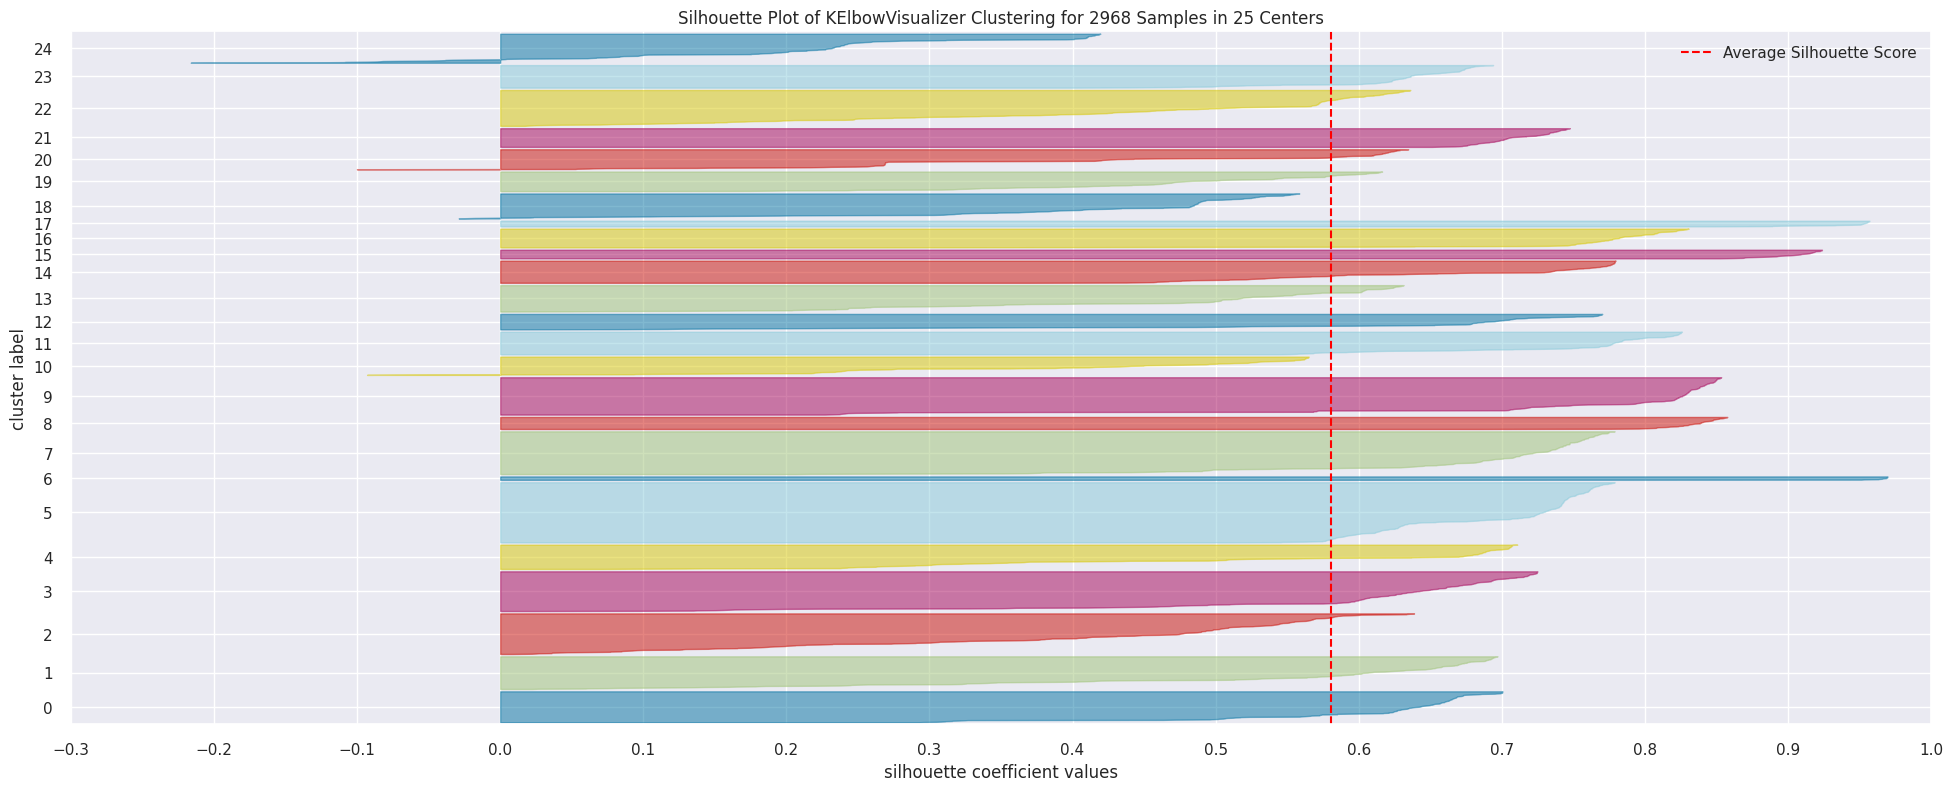

In [106]:
visualizer = SilhouetteVisualizer( kmeans, colors='yellowbrick')
visualizer.fit( X )
visualizer.finalize()

## 9.2 2d plot

In [107]:
#df_viz = df9.drop( columns='customer_id', axis=1)
#sns.pairplot( df_viz, hue='cluster')

## 9.3 UMAP

In [108]:
'''
reducer = umap.UMAP( n_neighbors=20, random_state=42 )
embedding = reducer.fit_transform( X )

# embedding
df_viz['embedding_x'] = embedding[:, 0]
df_viz['embedding_y'] = embedding[:, 1]

# plot UMAP
sns.scatterplot( x='embedding_x', y='embedding_y',
               hue='cluster',
               palette=sns.color_palette( 'hls', n_colors=len( df_viz['cluster'].unique() ) ),
               data=df_viz )

'''

"\nreducer = umap.UMAP( n_neighbors=20, random_state=42 )\nembedding = reducer.fit_transform( X )\n\n# embedding\ndf_viz['embedding_x'] = embedding[:, 0]\ndf_viz['embedding_y'] = embedding[:, 1]\n\n# plot UMAP\nsns.scatterplot( x='embedding_x', y='embedding_y',\n               hue='cluster',\n               palette=sns.color_palette( 'hls', n_colors=len( df_viz['cluster'].unique() ) ),\n               data=df_viz )\n\n"

## 9.2. Cluster Profile

In [109]:
df92 = df4[ cols_selected].copy()
df92['cluster'] = labels
df92.head()

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns,cluster
0,17850,5391.21,372.0,297.0,0.486111,40.0,3
1,13047,3232.59,56.0,171.0,0.048780,35.0,7
2,12583,6705.38,2.0,232.0,0.045699,50.0,3
3,13748,948.25,95.0,28.0,0.017921,0.0,6
4,15100,876.00,333.0,3.0,0.136364,22.0,2


In [110]:
# Number of customer
df_cluster = df92[['customer_id', 'cluster']].groupby( 'cluster' ).count().reset_index()
df_cluster['perc_customer'] = 100 * (df_cluster['customer_id'] / df_cluster['customer_id'].sum())

# Avg Gross revenue
df_avg_gross_revenue = df92[['gross_revenue', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_gross_revenue, how='inner', on='cluster')

# Avg receny days
df_avg_recency_days = df92[['recency_days', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_recency_days, how='inner', on='cluster')

# Avg invoice no
df_avg_invoice_no= df92[['qtde_products', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_invoice_no, how='inner', on='cluster')

# frequency
df_frequency= df92[['frequency', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_frequency, how='inner', on='cluster')

# returns
df_qtde_returns= df92[['qtde_returns', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_qtde_returns, how='inner', on='cluster')


df_cluster.sort_values(by='gross_revenue', ascending=False)

,cluster,customer_id,perc_customer,gross_revenue,recency_days,qtde_products,frequency,qtde_returns
3,3,468,15.768194,8836.136389,21.438034,424.134615,0.065622,149.271368
7,7,145,4.885445,3164.253379,34.427586,173.875862,0.065789,23.482759
1,1,465,15.667116,3108.146753,46.449462,120.627957,0.046671,26.584946
5,5,406,13.679245,1689.882315,54.731527,89.290640,0.041855,11.504926
4,4,436,14.690027,1209.422294,59.344037,57.229358,0.035527,8.688073
0,0,281,9.467655,956.602883,78.348754,36.587189,0.051608,5.661922
6,6,166,5.592992,837.752169,86.457831,27.608434,0.059569,12.415663
2,2,601,20.249326,555.032013,116.111481,14.139767,0.114863,9.670549


In [111]:
# 7 Cluster Insiders
# 6 Cluster More Products
# 4 Cluster Spend Money
# 5 Cluster Even More Products
# 3 Cluster Less Days
# 2 Cluster Less 1K
# 1 Cluster Stop Returns
# 0 Cluster More Buy

### Cluster 01: (Candidato a Insider)
    - Número de customers: 468 ( 16% do customers )
    - Faturamento médio: 8836
    - Recência média: 21 dias
    - Média de Produtos Comprados: 424 produtos
    - Frequência de produtos comprados: 0.09 produtos/dia 
    - Receita em média: $ 8.836,13 dólares

### Cluster 02:
    - Número de customers: 31 ( 0.71% do customers )
    - Recência média: 14 dias
    - Compras em média: 53 compras
    - Receita média: $40.543,52 dólares

### Cluster 03:
    - Número de customers: 4.335 ( 99% do customers )
    - Recência média: 92 dias
    - Compras em média: 5 compras
    - Receita média: $1.372,57 dólares

#  <font color='red'> 10.0. Análise Exploratória dos Dados </font>

In [112]:
df10 = df92.copy()

In [113]:
df10.head()

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns,cluster
0,17850,5391.21,372.0,297.0,0.486111,40.0,3
1,13047,3232.59,56.0,171.0,0.048780,35.0,7
2,12583,6705.38,2.0,232.0,0.045699,50.0,3
3,13748,948.25,95.0,28.0,0.017921,0.0,6
4,15100,876.00,333.0,3.0,0.136364,22.0,2


## 10.1. MindMap de hipóteses 

1. Fenômeno
2. Entidades (Customer, Location, Finace, Family, )
3. Caracteristicas da Entidade ( Customer=Nome, Idade, Salário, Escolaridade)

## 10.2. Hipóteses de Negócio

1. Afirmação.
2. Comparação entre variáveis.
3. Valor Base de comparação.

Cluster | Base de Comparação | Variável para Testar

## Hipóteses Compra

1. Os clientes do cluster insiders usam cartão de crédito em 80% das compras.
2. Os clientes do cluster insiders possuem um ticket médio de 10% acima do cluster More Products.
3. Os clientes do cluster insiders possuem um basket size acima de 5 produtos.
4. **Os clientes do cluster insiders possuem um volume (produtos) de compras acima de 10% do total de compras.**
5. **Os clientes do cluster insiders possuem um volume (faturamento) de compras acima de 10% do total de compras.**
6. **Os clientes do cluster insiders tem um número de devolução abaixo da média total de clientes.**
7. **A mediana do faturamento pelos clientes do cluster insider é 10% maior do que a mediana do faturamento geral**
8. **O percentil do gmv pelos clientes insiders**

### **H1: Os clientes do cluster insiders possuem um volume (produtos) de compras acima de 10% do total de compras.** 
**Verdade:** O Cluster insiders possui um volume de compras de produtos de 54%

In [114]:
# soma da qtde de valores do grupo insiders
df_sales_insiders = df10.loc[df10['cluster']==7, 'qtde_products' ].sum()

# soma da qtde de valores do grupo toal
df_sales_total = df10.loc[:, 'qtde_products'].sum()

print('% Sales Insiders: {:.2f}%'.format( 100* df_sales_insiders / df_sales_total ))

% Sales Insiders: 6.92%


### **H2: Os clientes do cluster insiders possuem um volume (faturamento) de compras acima de 10% do total de compras.** 
**Verdade:** O Cluster insiders possui um volume de GMV de 52%

In [115]:
# soma da qtde de valores do grupo insiders
df_gmv_insiders = df10.loc[df10['cluster']==7, 'gross_revenue' ].sum()

# soma da qtde de valores do grupo toal
df_gmv_total = df10.loc[:, 'gross_revenue'].sum()

print('% Sales Insiders: {:.2f}%'.format( 100* df_gmv_insiders / df_gmv_total ))

% Sales Insiders: 5.74%


### **H3: Os clientes do cluster insiders tem um número de devolução abaixo da média total de clientes.**
**False** O cluster insiders tem média de devoluções acima da média geral

In [116]:
# media de devolução do insiders
df_avg_return_insiders = df10.loc[df10['cluster']==7, 'qtde_returns'].mean()

# media de devolução total
df_avg_return_total = df10.loc[:, 'qtde_returns'].mean()

print('Avg Return Insiders: {} vs Avg Return All : {}'.format(np.round(df_avg_return_insiders,0), np.round(df_avg_return_total,0)))

Avg Return Insiders: 23.0 vs Avg Return All : 35.0


### **H4: A mediana do faturamento pelos clientes do cluster insider é 10% maior do que a mediana do faturamento geral**

In [117]:
# mediana de gmv do insiders
df_median_gmv_insiders = df10.loc[df10['cluster']==7, 'gross_revenue'].median()

# mediana de gmv do total
df_median_gmv_total = df10.loc[:, 'gross_revenue'].median()

gmv_diff = (df_median_gmv_insiders - df_median_gmv_total) / df_median_gmv_total

print( 'Median Diff: {:2f}'.format(100*gmv_diff))

Median Diff: 164.945509


### **H5: O GMV dos clientes insiders estão concentrados no 3 quartil**
**Falso** O faturamento do cluster insiders está concentrada no quartil 1

In [118]:
np.percentile( df10.loc[df10['cluster']==7, 'gross_revenue'], q=10)

np.float64(749.43)

In [119]:
np.percentile( df10.loc[df10['cluster']==7, 'gross_revenue'], q=90)

np.float64(4807.412)

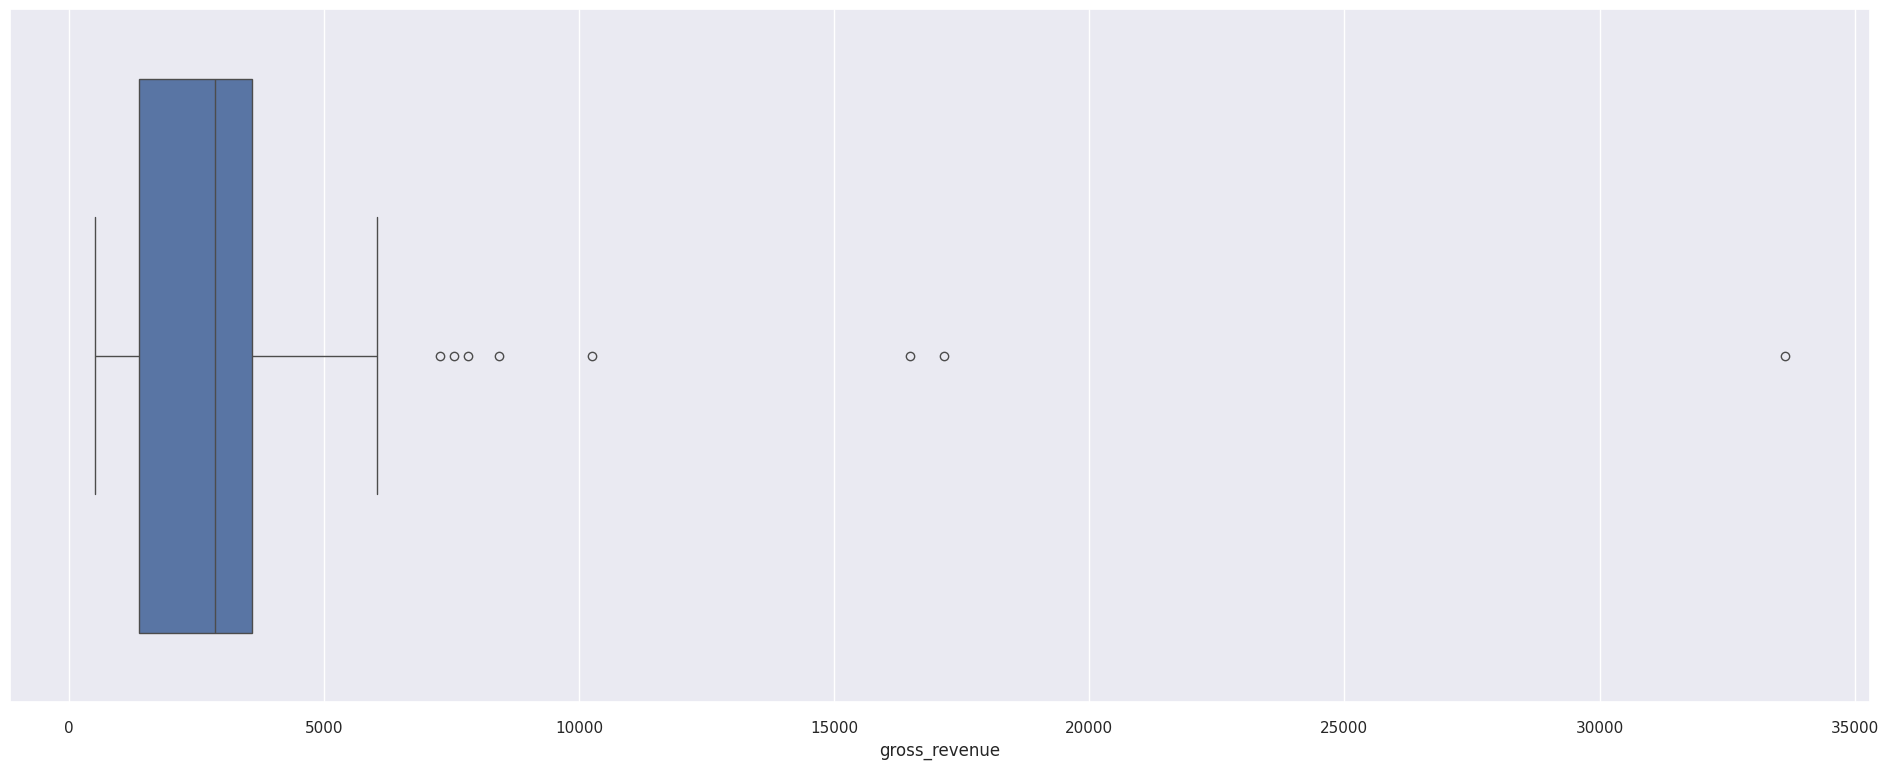

In [120]:
sns.boxplot( x=df10.loc[df10['cluster']==7,'gross_revenue'] );

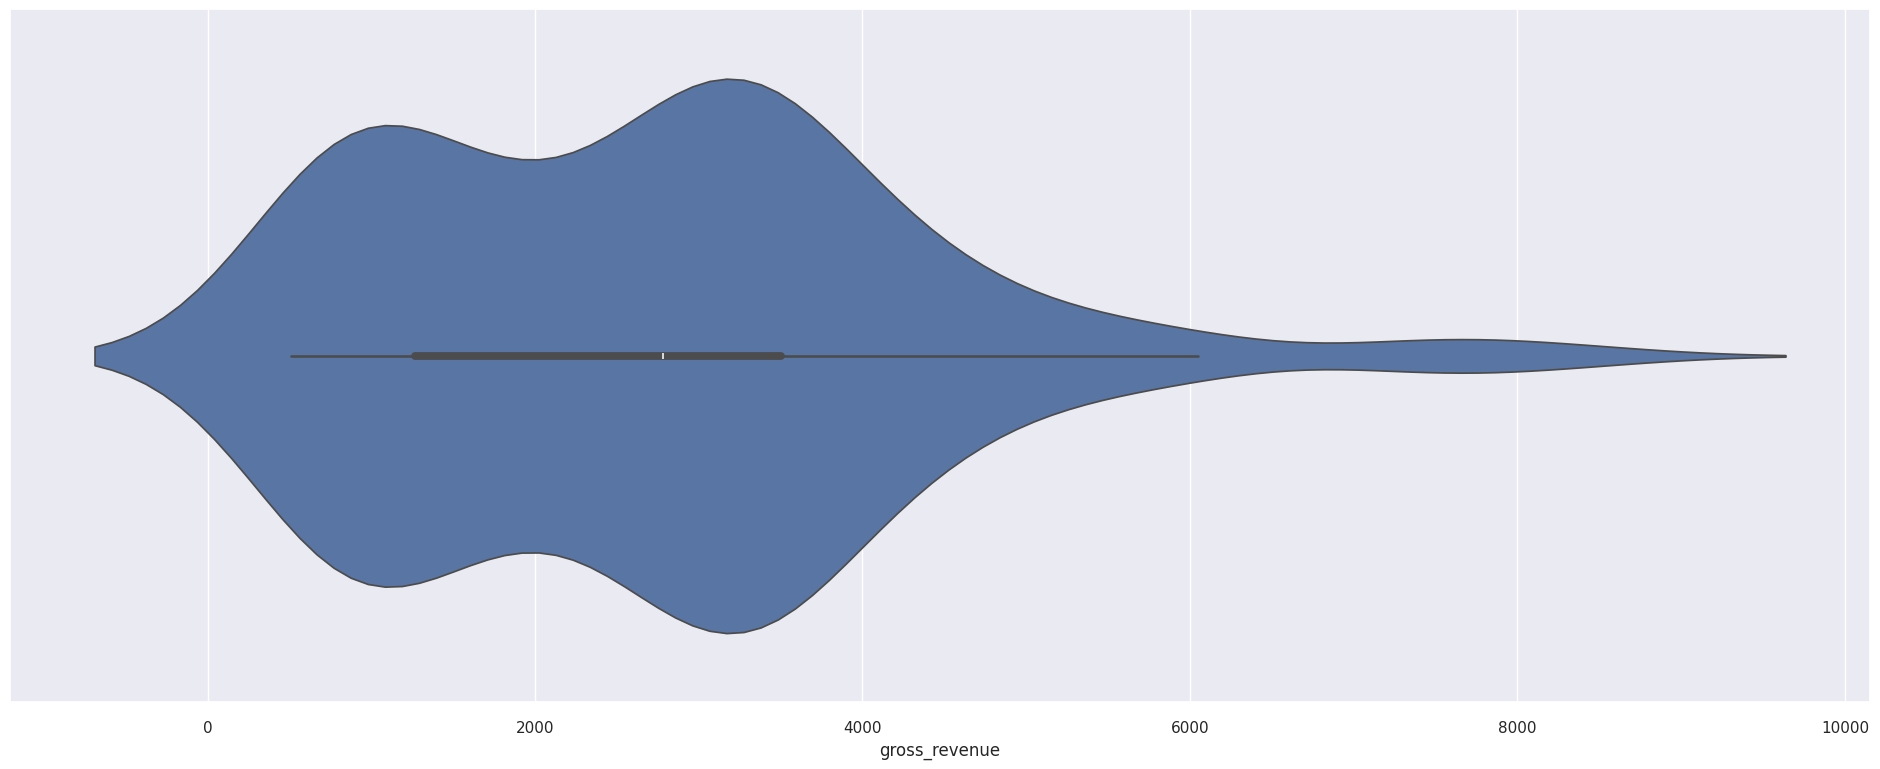

In [121]:
df_aux = df10.loc[(df10['cluster']==7) & (df10['gross_revenue'] < 10000),'gross_revenue']
sns.violinplot( x=df_aux );

## Hipóteses Cliente

1. 60% dos clientes do cluster insiders possuem o estado civil de solteiro.
2. 10% dos clientes do cluster insiders estão na faixa de 24-35 anos.
3. 40% das localidades de entrega do cluster insiders estão dentro de um raio de 50km.
4. 5% dos clientes do cluster insiders recebem mais de 100 mil dólares anualmente
5. 90% dos clientes do cluster insiders tem ensino superior completo

## Hipóteses Produto

1. 30% de todos os produtos em pacotes grandes são comprados pelos clientes do cluster insiders
2. A mediana do faturamento pelos clientes do cluster insider é 10% maior do que a mediana de todos os preços dos produtos
3. O percentil do preço dos produtos comprados pelos clientes insiders
4. O peso médio dos produtos comprados pelos clientes do cluster insiders é maior do que o peso médios dos outros clusters
5. A Idade média dos produtos comprados pelos clientes do cluster insiders é menor do que 15 dias

1. Afirmação
2. Comparação entre variáveis
3. Valor base de comparação

## Perguntas de Negócio

In [122]:
df10.head()

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns,cluster
0,17850,5391.21,372.0,297.0,0.486111,40.0,3
1,13047,3232.59,56.0,171.0,0.048780,35.0,7
2,12583,6705.38,2.0,232.0,0.045699,50.0,3
3,13748,948.25,95.0,28.0,0.017921,0.0,6
4,15100,876.00,333.0,3.0,0.136364,22.0,2


## 1. Quem são as pessoas elegíveis para participar do programa de insider?

In [123]:
df10.loc[df10['cluster']==7, 'customer_id'].head()

1     13047
28    14307
54    15525
76    13093
92    18229
Name: customer_id, dtype: int64

## 2. Quantos clientes farão parte do grupo?

In [124]:
df10.loc[df10['cluster']==7, 'customer_id'].size

145

## 3. Quais as principais características desses clientes?

### Cluster 01: (Candidato a Insider)
    - Número de customers: 468 ( 16% do customers )
    - Faturamento médio: 8836
    - Recência média: 21 dias
    - Média de Produtos Comprados: 424 produtos
    - Frequência de produtos comprados: 0.09 produtos/dia 
    - Receita em média: $ 8.836,13 dólares

In [125]:
import scipy.stats as st

In [126]:
df_insiders = df10.loc[df10['cluster'] == 7, 'gross_revenue']

# Via Bootstrap
st.t.interval( confidence=0.95,
               df = len(df_insiders)-1,
               loc = np.mean(df_insiders),
               scale = st.sem( df_insiders)
              )

(np.float64(2592.6254575897856), np.float64(3735.881301030904))

In [127]:
np.mean( df_insiders )

np.float64(3164.253379310345)

4. Qual a porcentagem de contribuição do faturamento, vinda do Insiders?

In [128]:
df_insiders_gmv = df10.loc[df10['cluster']==7, 'gross_revenue'].sum()
df_all_gmv = df10.loc[:, 'gross_revenue'].sum()

print( '% GMV from Insiders: {}'.format( df_insiders_gmv / df_all_gmv))

% GMV from Insiders: 0.05739324589652076


5. Qual a expectativa de faturamento desse grupo para os próximos meses?

6. Quais as condições para uma pessoa ser elegível ao Insiders?

7. Quais as condições para uma pessoa ser removida do Insiders?

8. Qual a garantia que o programa Insiders é melhor que o restante da base?

9. Quais ações o time de marketing pode realizar para aumentar o faturamento?   

## 10.3. Priorização das Hipóteses

## 10.4. Validação das Hipóteses

## 10.5. Quadro de Respostas

#  <font color='red'> 11.0. Deploy to Production </font>

In [129]:
# plano
# TMUX